In [ ]:
from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
import os

print(os.listdir('/content/drive/MyDrive'))

['IMG-20240707-WA0062.jpg', '24I-2617-tooba qasim-DS(A).pdf', 'Classroom', '24i-2617.pdf', 'Tooba Binte - Assignment # 1.gdoc', 'CamScanner09-11-202423.56.pdf', 'task2.pptx', 'Tooba Binte - PowerPoint.gdoc', 'task1.pptx', 'Floor Plans.pdf', 'AttendanceSheet (1).gsheet', 'AttendanceSheet.gsheet', 'AttendanceSheet(24i26176).xlsx', 'drinks124i2617.xlsx', '24I-2617.xlsx', 'Tooba Binte - Week # 06(Excel lab 2).gdoc', 'My Resume-24i-2617.pdf', 'Tooba Binte - PowerPoint Presentation.gdoc', '242617.zip', 'booksstore_inventory.accdb', 'The Holy Prophet (PBUH) as a Leader.gslides', 'AttendanceSheet(24i26176).gsheet', '24i-2617--ToobaQasim-DS-A.pdf', '11. HTML Lab.gdoc', 'assign4.cpp.zip', 'group number _self marking_all group member name (1).docx', 'word shooter..2421840-DSA.zip', '2421840 (1).pdf', '2421840.pdf', 'CamScanner16-03-202523.26.pdf', 'assignment 1..24i-2617....ds-A.zip', 'ToobaQasim,24i-2617,DS-2A.pdf', 'Voice over', 'M. Morris Mano, Michael D. Ciletti - Digital Design_ With an Intr

In [ ]:
import os

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if file in ["train_transaction.csv", "train_identity.csv"]:
            print(os.path.join(root, file))

/content/drive/MyDrive/Fraud_Detection_Project/train_identity.csv
/content/drive/MyDrive/Fraud_Detection_Project/train_transaction.csv


In [ ]:
import pandas as pd

transaction_path = "/content/drive/MyDrive/Fraud_Detection_Project/train_transaction.csv"
identity_path = "/content/drive/MyDrive/Fraud_Detection_Project/train_identity.csv"

train_transaction = pd.read_csv(transaction_path, low_memory=False)
train_identity = pd.read_csv(identity_path, low_memory=False)

print("Transaction shape:", train_transaction.shape)
print("Identity shape:", train_identity.shape)

Transaction shape: (590540, 394)
Identity shape: (144233, 41)


In [ ]:
# Merge transaction and identity datasets
df = train_transaction.merge(
    train_identity,
    on="TransactionID",
    how="left"
)

# Sort transactions chronologically
df = df.sort_values("TransactionDT").reset_index(drop=True)

print("Merged dataset shape:", df.shape)
print("\nFraud distribution:")
print(df["isFraud"].value_counts())

print("\nFraud percentages:")
print(df["isFraud"].value_counts(normalize=True) * 100)

print("\nMissing values (top 15):")
print(df.isnull().sum().sort_values(ascending=False).head(15))

Merged dataset shape: (590540, 434)

Fraud distribution:
isFraud
0    569877
1     20663
Name: count, dtype: int64

Fraud percentages:
isFraud
0    96.500999
1     3.499001
Name: proportion, dtype: float64

Missing values (top 15):
id_24    585793
id_25    585408
id_07    585385
id_08    585385
id_21    585381
id_26    585377
id_27    585371
id_23    585371
id_22    585371
dist2    552913
D7       551623
id_18    545427
D13      528588
D14      528353
D12      525823
dtype: int64


In [ ]:
# Chronological split
n = len(df)

train_end = int(n * 0.70)
val_end = int(n * 0.80)

train_df = df.iloc[:train_end].copy()
val_df = df.iloc[train_end:val_end].copy()
test_df = df.iloc[val_end:].copy()

# Check split sizes and fraud distribution
for name, data in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    print(f"\n{name} dataset")
    print("Shape:", data.shape)
    print("Fraud distribution:")
    print(data["isFraud"].value_counts())
    print("Fraud percentage:", round(data["isFraud"].mean() * 100, 2), "%")


Training dataset
Shape: (413378, 434)
Fraud distribution:
isFraud
0    398840
1     14538
Name: count, dtype: int64
Fraud percentage: 3.52 %

Validation dataset
Shape: (59054, 434)
Fraud distribution:
isFraud
0    56993
1     2061
Name: count, dtype: int64
Fraud percentage: 3.49 %

Testing dataset
Shape: (118108, 434)
Fraud distribution:
isFraud
0    114044
1      4064
Name: count, dtype: int64
Fraud percentage: 3.44 %


In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import OrdinalEncoder

# Calculate statistics using training data only

global_median = train_df["TransactionAmt"].median()

product_medians = train_df.groupby("ProductCD")["TransactionAmt"].median()

p_email_counts = train_df["P_emaildomain"].value_counts()
r_email_counts = train_df["R_emaildomain"].value_counts()


# Feature engineering function

def add_features(data):
    data = data.copy()

    data["Amount_Relative_To_Product"] = (
        data["TransactionAmt"] /
        data["ProductCD"].map(product_medians)
    )

    data["Amount_Relative_To_Product"] = (
        data["Amount_Relative_To_Product"].fillna(
            data["TransactionAmt"] / global_median
        )
    )

    data["P_emaildomain_Frequency"] = (
        data["P_emaildomain"].map(p_email_counts).fillna(0)
    )

    data["R_emaildomain_Frequency"] = (
        data["R_emaildomain"].map(r_email_counts).fillna(0)
    )

    return data


# Apply features to all three splits

train_df = add_features(train_df)
val_df = add_features(val_df)
test_df = add_features(test_df)


# Separate features and target

drop_cols = ["isFraud", "TransactionID"]

X_train = train_df.drop(columns=drop_cols)
y_train = train_df["isFraud"]

X_val = val_df.drop(columns=drop_cols)
y_val = val_df["isFraud"]

X_test = test_df.drop(columns=drop_cols)
y_test = test_df["isFraud"]


# Identify categorical columns

cat_cols = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()


# Encode categories using training data only

encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1,
    encoded_missing_value=-1,
    dtype=np.float32
)

X_train[cat_cols] = encoder.fit_transform(
    X_train[cat_cols].astype("object")
)

X_val[cat_cols] = encoder.transform(
    X_val[cat_cols].astype("object")
)

X_test[cat_cols] = encoder.transform(
    X_test[cat_cols].astype("object")
)


# Replace infinite values with missing values

for data in [X_train, X_val, X_test]:
    data.replace([np.inf, -np.inf], np.nan, inplace=True)


# Final checks

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Testing features:", X_test.shape)

print("\nCategorical columns encoded:", len(cat_cols))

print("\nMissing values in training features:", X_train.isnull().sum().sum())

print("\nPreprocessing completed successfully.")

Training features: (413378, 435)
Validation features: (59054, 435)
Testing features: (118108, 435)

Categorical columns encoded: 31

Missing values in training features: 72374378

Preprocessing completed successfully.


In [ ]:
%pip install -q xgboost

In [ ]:
import xgboost as xgb
import numpy as np

from sklearn.metrics import (
    precision_recall_curve,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score
)

# Calculate class imbalance weight
scale_weight = (y_train == 0).sum() / (y_train == 1).sum()

print("XGBoost version:", xgb.__version__)
print("Scale positive weight:", round(scale_weight, 2))

# Configure model
model = xgb.XGBClassifier(
    n_estimators=1000,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_weight,
    objective="binary:logistic",
    eval_metric="aucpr",
    tree_method="hist",
    max_bin=256,
    early_stopping_rounds=50,
    random_state=42,
    n_jobs=-1
)

# Train
model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    verbose=100
)

print("\nBest iteration:", model.best_iteration)

XGBoost version: 3.4.1
Scale positive weight: 27.43
[0]	validation_0-aucpr:0.31147
[100]	validation_0-aucpr:0.54168
[200]	validation_0-aucpr:0.57368
[300]	validation_0-aucpr:0.59254
[400]	validation_0-aucpr:0.60455
[500]	validation_0-aucpr:0.61382
[600]	validation_0-aucpr:0.62427
[700]	validation_0-aucpr:0.62704
[800]	validation_0-aucpr:0.63525
[865]	validation_0-aucpr:0.63610

Best iteration: 815


In [ ]:
# Validation probabilities
val_probs = model.predict_proba(X_val)[:, 1]

# Find best F1 threshold
precision, recall, thresholds = precision_recall_curve(
    y_val,
    val_probs
)

f1_scores = (
    2 * precision[:-1] * recall[:-1] /
    (precision[:-1] + recall[:-1] + 1e-10)
)

best_index = np.argmax(f1_scores)
best_threshold = thresholds[best_index]

print("Best validation threshold:", round(best_threshold, 4))
print("Best validation F1:", round(f1_scores[best_index], 4))

Best validation threshold: 0.6645
Best validation F1: 0.6022


In [ ]:
test_probs = model.predict_proba(X_test)[:, 1]
test_preds = (test_probs >= best_threshold).astype(int)

print("FINAL TEST RESULTS")
print("--------------------------")

print("Precision:", round(precision_score(y_test, test_preds), 4))
print("Recall:", round(recall_score(y_test, test_preds), 4))
print("F1 Score:", round(f1_score(y_test, test_preds), 4))
print("PR-AUC:", round(average_precision_score(y_test, test_probs), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, test_probs), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_preds))

print("\nClassification Report:")
print(classification_report(y_test, test_preds))

FINAL TEST RESULTS
--------------------------
Precision: 0.5629
Recall: 0.4341
F1 Score: 0.4901
PR-AUC: 0.5044
ROC-AUC: 0.8971

Confusion Matrix:
[[112674   1370]
 [  2300   1764]]

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.98    114044
           1       0.56      0.43      0.49      4064

    accuracy                           0.97    118108
   macro avg       0.77      0.71      0.74    118108
weighted avg       0.97      0.97      0.97    118108



In [ ]:

import pandas as pd
import joblib

# Save model
joblib.dump(model, "/content/xgboost_fraud_model.pkl")

# Save test predictions
predictions = pd.DataFrame({
    "TransactionID": test_df["TransactionID"].values,
    "Actual": y_test.values,
    "Fraud_Probability": test_probs,
    "Predicted": test_preds
})

predictions.to_csv(
    "/content/xgboost_test_predictions.csv",
    index=False
)

# Save evaluation metrics
results = pd.DataFrame({
    "Metric": [
        "Precision",
        "Recall",
        "F1 Score",
        "PR-AUC",
        "ROC-AUC",
        "Best Threshold",
        "Best Iteration"
    ],
    "Value": [
        precision_score(y_test, test_preds),
        recall_score(y_test, test_preds),
        f1_score(y_test, test_preds),
        average_precision_score(y_test, test_probs),
        roc_auc_score(y_test, test_probs),
        best_threshold,
        model.best_iteration
    ]
})

results.to_csv("/content/xgboost_results.csv", index=False)

print("Model and evaluation results saved.")

Model and evaluation results saved.


In [ ]:
import os
import joblib
import pandas as pd

# Create project folder in Google Drive
save_folder = "/content/drive/MyDrive/Fraud_Detection_Project/Model_Results"
os.makedirs(save_folder, exist_ok=True)

# Save trained model and preprocessing information
joblib.dump({
    "model": model,
    "encoder": encoder,
    "product_medians": product_medians,
    "p_email_counts": p_email_counts,
    "r_email_counts": r_email_counts,
    "global_median": global_median,
    "best_threshold": best_threshold
}, os.path.join(save_folder, "xgboost_complete.pkl"))

# Save test predictions
predictions.to_csv(
    os.path.join(save_folder, "xgboost_test_predictions.csv"),
    index=False
)

# Save evaluation metrics
results.to_csv(
    os.path.join(save_folder, "xgboost_results.csv"),
    index=False
)

print("All XGBoost artifacts saved to Google Drive!")
print("Location:", save_folder)
print(os.listdir(save_folder))

All XGBoost artifacts saved to Google Drive!
Location: /content/drive/MyDrive/Fraud_Detection_Project/Model_Results
['xgboost_complete.pkl', 'xgboost_test_predictions.csv', 'xgboost_results.csv']


In [ ]:
print(X_train.shape)
print(X_val.shape)
print(X_test.shape)
print(cat_cols[:5])

(413378, 435)
(59054, 435)
(118108, 435)
['ProductCD', 'card4', 'card6', 'P_emaildomain', 'R_emaildomain']


In [ ]:

import os
import time
import joblib
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    confusion_matrix
)

# Google Drive output folder
save_folder = "/content/drive/MyDrive/Fraud_Detection_Project/Model_Results"
os.makedirs(save_folder, exist_ok=True)

# Identify feature types
cat_cols = list(cat_cols)
num_cols = [c for c in X_train.columns if c not in cat_cols]

# Convert categorical codes back to categorical values.
# -1 represents unknown or missing categories.
Xtr = X_train.copy()
Xv = X_val.copy()
Xte = X_test.copy()

for col in cat_cols:
    Xtr[col] = Xtr[col].replace(-1, np.nan)
    Xv[col] = Xv[col].replace(-1, np.nan)
    Xte[col] = Xte[col].replace(-1, np.nan)

# Numeric preprocessing for Logistic Regression
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing for Logistic Regression
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=20
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, num_cols),
    ("categorical", categorical_pipeline, cat_cols)
])

# Evaluation and saving function
def evaluate_and_save(name, model, start_time):

    val_probs = model.predict_proba(Xv)[:, 1]

    precision, recall, thresholds = precision_recall_curve(
        y_val, val_probs
    )

    f1_values = (
        2 * precision[:-1] * recall[:-1] /
        (precision[:-1] + recall[:-1] + 1e-10)
    )

    best_idx = np.argmax(f1_values)
    threshold = thresholds[best_idx]

    test_probs = model.predict_proba(Xte)[:, 1]
    test_preds = (test_probs >= threshold).astype(int)

    cm = confusion_matrix(y_test, test_preds)

    metrics = {
        "Model": name,
        "Threshold": threshold,
        "Precision": precision_score(y_test, test_preds),
        "Recall": recall_score(y_test, test_preds),
        "F1": f1_score(y_test, test_preds),
        "PR_AUC": average_precision_score(y_test, test_probs),
        "ROC_AUC": roc_auc_score(y_test, test_probs),
        "TN": cm[0, 0],
        "FP": cm[0, 1],
        "FN": cm[1, 0],
        "TP": cm[1, 1],
        "Training_Time_Minutes": (time.time() - start_time) / 60
    }

    # Save model
    joblib.dump(
        model,
        os.path.join(save_folder, name.lower() + "_model.pkl")
    )

    # Save test predictions
    pd.DataFrame({
        "TransactionID": test_df["TransactionID"].values,
        "Actual": y_test.values,
        "Fraud_Probability": test_probs,
        "Predicted": test_preds
    }).to_csv(
        os.path.join(save_folder, name.lower() + "_predictions.csv"),
        index=False
    )

    # Save confusion matrix
    pd.DataFrame(
        cm,
        index=["Actual_Legitimate", "Actual_Fraud"],
        columns=["Predicted_Legitimate", "Predicted_Fraud"]
    ).to_csv(
        os.path.join(save_folder, name.lower() + "_confusion_matrix.csv")
    )

    pd.DataFrame([metrics]).to_csv(
        os.path.join(save_folder, name.lower() + "_results.csv"),
        index=False
    )

    print(f"\n{name} completed and saved.")
    print(pd.Series(metrics).to_string())

    return metrics


all_results = []

# 1. Logistic Regression
print("\nStarting Logistic Regression...")
start = time.time()

lr_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        solver="saga",
        max_iter=100,
        tol=1e-3,
        random_state=42,
        n_jobs=-1,
        verbose=1
    ))
])

lr_model.fit(Xtr, y_train)

all_results.append(
    evaluate_and_save("Logistic_Regression", lr_model, start)
)

# Save progress immediately
pd.DataFrame(all_results).to_csv(
    os.path.join(save_folder, "baseline_comparison.csv"),
    index=False
)

# 2. Random Forest
print("\nStarting Random Forest...")
start = time.time()

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_model.fit(Xtr, y_train)

all_results.append(
    evaluate_and_save("Random_Forest", rf_model, start)
)

# Final baseline comparison
comparison = pd.DataFrame(all_results)

# Add previously saved XGBoost test results
xgb_results = pd.read_csv(
    os.path.join(save_folder, "xgboost_results.csv")
)

xgb_row = {
    "Model": "XGBoost",
    "Threshold": float(
        xgb_results.loc[
            xgb_results["Metric"] == "Best Threshold", "Value"
        ].iloc[0]
    )
}

for metric in ["Precision", "Recall", "F1", "PR-AUC", "ROC-AUC"]:
    xgb_row[metric.replace("-", "_").replace(" ", "_")] = float(
        xgb_results.loc[
            xgb_results["Metric"] == metric, "Value"
        ].iloc[0]
    )

# Align column names
comparison = comparison.rename(columns={
    "PR_AUC": "PR_AUC",
    "ROC_AUC": "ROC_AUC"
})

comparison = pd.concat(
    [pd.DataFrame([xgb_row]), comparison],
    ignore_index=True
)

comparison.to_csv(
    os.path.join(save_folder, "baseline_comparison.csv"),
    index=False
)

print("\nALL BASELINE EXPERIMENTS COMPLETED")
print(comparison.to_string(index=False))
print("\nSaved in:", save_folder)



Starting Logistic Regression...


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

folder = "/content/drive/MyDrive/Fraud_Detection_Project/Model_Results"

print(os.listdir(folder))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['xgboost_complete.pkl', 'xgboost_test_predictions.csv', 'xgboost_results.csv']


In [ ]:
required = ["X_train", "X_val", "X_test", "y_train", "y_val", "y_test"]

for name in required:
    print(name, "available" if name in globals() else "missing")

X_train missing
X_val missing
X_test missing
y_train missing
y_val missing
y_test missing


In [ ]:
import os

base = "/content/drive/MyDrive"

transaction_path = None
identity_path = None

for root, dirs, files in os.walk(base):
    if "train_transaction.csv" in files:
        transaction_path = os.path.join(root, "train_transaction.csv")

    if "train_identity.csv" in files:
        identity_path = os.path.join(root, "train_identity.csv")

    if transaction_path and identity_path:
        break

print("Transaction file:", transaction_path)
print("Identity file:", identity_path)

Transaction file: /content/drive/MyDrive/Fraud_Detection_Project/train_transaction.csv
Identity file: /content/drive/MyDrive/Fraud_Detection_Project/train_identity.csv


In [ ]:
!pip install -q xgboost

import xgboost
from xgboost import XGBClassifier

import pickle
import os
import sys

print("XGBoost version:", xgboost.__version__)
print("XGBClassifier imported successfully.")

folder = "/content/drive/MyDrive/Fraud_Detection_Project/Model_Results"

with open(os.path.join(folder, "xgboost_complete.pkl"), "rb") as f:
    saved = pickle.load(f)

print("\nSaved components:", list(saved.keys()))

XGBoost version: 3.4.1
XGBClassifier imported successfully.


ModuleNotFoundError: No module named 'XGBClassifier'

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import pandas as pd
import numpy as np

base_path = "/content/drive/MyDrive/Fraud_Detection_Project"

transaction_path = os.path.join(base_path, "train_transaction.csv")
identity_path = os.path.join(base_path, "train_identity.csv")
results_path = os.path.join(base_path, "Model_Results")

os.makedirs(results_path, exist_ok=True)

train_transaction = pd.read_csv(transaction_path, low_memory=False)
train_identity = pd.read_csv(identity_path, low_memory=False)

df = train_transaction.merge(
    train_identity,
    on="TransactionID",
    how="left"
)

df = df.sort_values("TransactionDT").reset_index(drop=True)

print("Transaction data:", train_transaction.shape)
print("Identity data:", train_identity.shape)
print("Merged dataset:", df.shape)

print("\nClass distribution:")
print(df["isFraud"].value_counts())
print("\nFraud percentage:")
print(round(df["isFraud"].mean() * 100, 2), "%")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Transaction data: (590540, 394)
Identity data: (144233, 41)
Merged dataset: (590540, 434)

Class distribution:
isFraud
0    569877
1     20663
Name: count, dtype: int64

Fraud percentage:
3.5 %


In [ ]:
import gc
from sklearn.preprocessing import OrdinalEncoder

# Free memory used by the original CSV dataframes
del train_transaction, train_identity
gc.collect()

# Chronological split
n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.80)

train_df = df.iloc[:train_end].copy()
val_df = df.iloc[train_end:val_end].copy()
test_df = df.iloc[val_end:].copy()

print("Split shapes:")
print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

print("\nFraud rates:")
print("Train:", round(train_df["isFraud"].mean() * 100, 2), "%")
print("Validation:", round(val_df["isFraud"].mean() * 100, 2), "%")
print("Test:", round(test_df["isFraud"].mean() * 100, 2), "%")

# Target variables
y_train = train_df["isFraud"].astype("int8")
y_val = val_df["isFraud"].astype("int8")
y_test = test_df["isFraud"].astype("int8")

# Training-only statistics for feature engineering
global_median = train_df["TransactionAmt"].median()

product_medians = train_df.groupby("ProductCD")["TransactionAmt"].median()

p_email_counts = train_df["P_emaildomain"].value_counts().to_dict()
r_email_counts = train_df["R_emaildomain"].value_counts().to_dict()

# Apply the same feature engineering to each split
def engineer_features(data):
    data = data.copy()

    data["Amount_Relative_To_Product"] = (
        data["TransactionAmt"] /
        data["ProductCD"].map(product_medians).fillna(global_median)
    )

    data["P_emaildomain_Frequency"] = (
        data["P_emaildomain"].map(p_email_counts)
    )

    data["R_emaildomain_Frequency"] = (
        data["R_emaildomain"].map(r_email_counts)
    )

    return data

train_features = engineer_features(train_df)
val_features = engineer_features(val_df)
test_features = engineer_features(test_df)

# Remove target and transaction ID from model inputs
X_train = train_features.drop(columns=["isFraud", "TransactionID"])
X_val = val_features.drop(columns=["isFraud", "TransactionID"])
X_test = test_features.drop(columns=["isFraud", "TransactionID"])

# Identify categorical columns
cat_cols = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Fit encoder only on training data
encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1,
    encoded_missing_value=-1,
    dtype=np.float32
)

X_train[cat_cols] = encoder.fit_transform(X_train[cat_cols])
X_val[cat_cols] = encoder.transform(X_val[cat_cols])
X_test[cat_cols] = encoder.transform(X_test[cat_cols])

# Ensure numeric data and preserve missing values
X_train = X_train.astype(np.float32)
X_val = X_val.astype(np.float32)
X_test = X_test.astype(np.float32)

X_train = X_train.replace([np.inf, -np.inf], np.nan)
X_val = X_val.replace([np.inf, -np.inf], np.nan)
X_test = X_test.replace([np.inf, -np.inf], np.nan)

feature_names = X_train.columns.tolist()

print("\nPreprocessing complete.")
print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Testing features:", X_test.shape)
print("Categorical columns:", len(cat_cols))
print("Total features:", len(feature_names))
print("Training missing cells:", X_train.isna().sum().sum())

assert X_train.shape[1] == X_val.shape[1] == X_test.shape[1]
assert feature_names == X_val.columns.tolist() == X_test.columns.tolist()
assert "isFraud" not in feature_names
assert "TransactionID" not in feature_names

# Release intermediate dataframes
del train_features, val_features, test_features
gc.collect()

Split shapes:
Train: (413378, 434)
Validation: (59054, 434)
Test: (118108, 434)

Fraud rates:
Train: 3.52 %
Validation: 3.49 %
Test: 3.44 %

Preprocessing complete.
Training features: (413378, 435)
Validation features: (59054, 435)
Testing features: (118108, 435)
Categorical columns: 31
Total features: 435
Training missing cells: 72749011


0

In [ ]:
!pip install -q xgboost==3.4.1

import xgboost as xgb
import joblib
import json
import gc
import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    average_precision_score, roc_auc_score,
    confusion_matrix, classification_report,
    precision_recall_curve
)
from xgboost import XGBClassifier

print("XGBoost version:", xgb.__version__)

scale_weight = (len(y_train) - y_train.sum()) / y_train.sum()

model = XGBClassifier(
    n_estimators=1000,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_weight,
    objective="binary:logistic",
    eval_metric="aucpr",
    tree_method="hist",
    max_bin=256,
    early_stopping_rounds=50,
    random_state=42,
    n_jobs=-1
)

model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    verbose=100
)

print("\nBest iteration:", model.best_iteration)

# Select threshold using validation data only
val_probs = model.predict_proba(X_val)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_val, val_probs
)

f1_scores = (
    2 * precision[:-1] * recall[:-1] /
    (precision[:-1] + recall[:-1] + 1e-12)
)

best_idx = np.argmax(f1_scores)
best_threshold = float(thresholds[best_idx])

print("Best validation threshold:", best_threshold)
print("Best validation F1:", f1_scores[best_idx])

# Final test evaluation
test_probs = model.predict_proba(X_test)[:, 1]
test_preds = (test_probs >= best_threshold).astype(int)

metrics = {
    "Precision": precision_score(y_test, test_preds),
    "Recall": recall_score(y_test, test_preds),
    "F1": f1_score(y_test, test_preds),
    "PR_AUC": average_precision_score(y_test, test_probs),
    "ROC_AUC": roc_auc_score(y_test, test_probs)
}

print("\nTEST RESULTS")
for name, value in metrics.items():
    print(f"{name}: {value:.4f}")

print("\nConfusion matrix:")
print(confusion_matrix(y_test, test_preds))

print("\nClassification report:")
print(classification_report(y_test, test_preds))

# Save native XGBoost model
model_path = os.path.join(results_path, "xgboost_model.json")
model.save_model(model_path)

# Save preprocessing artifacts
joblib.dump(
    {
        "encoder": encoder,
        "product_medians": product_medians,
        "p_email_counts": p_email_counts,
        "r_email_counts": r_email_counts,
        "global_median": global_median,
        "feature_names": feature_names,
        "cat_cols": cat_cols,
        "best_threshold": best_threshold
    },
    os.path.join(results_path, "xgboost_preprocessing.joblib")
)

# Save test predictions with actual labels
pd.DataFrame({
    "TransactionID": test_df["TransactionID"].values,
    "Actual": y_test.values,
    "Fraud_Probability": test_probs,
    "Predicted": test_preds
}).to_csv(
    os.path.join(results_path, "xgboost_test_predictions_retrained.csv"),
    index=False
)

pd.DataFrame([metrics]).to_csv(
    os.path.join(results_path, "xgboost_test_metrics_retrained.csv"),
    index=False
)

# Verify that the saved model can be reloaded
loaded_model = XGBClassifier()
loaded_model.load_model(model_path)

check_probs = loaded_model.predict_proba(X_test.iloc[:100])[:, 1]

assert np.allclose(check_probs, test_probs[:100], atol=1e-6)

print("\nSUCCESS: Model saved and reload verification passed.")
print("Saved to:", results_path)

del loaded_model, check_probs
gc.collect()

XGBoost version: 3.4.1
[0]	validation_0-aucpr:0.31147
[100]	validation_0-aucpr:0.52794
[200]	validation_0-aucpr:0.56537
[300]	validation_0-aucpr:0.58223
[400]	validation_0-aucpr:0.59797
[500]	validation_0-aucpr:0.60466
[600]	validation_0-aucpr:0.61574
[700]	validation_0-aucpr:0.62280
[800]	validation_0-aucpr:0.62891
[900]	validation_0-aucpr:0.63299
[999]	validation_0-aucpr:0.63931

Best iteration: 999
Best validation threshold: 0.5736070275306702
Best validation F1: 0.6059498956153692

TEST RESULTS
Precision: 0.5272
Recall: 0.4658
F1: 0.4946
PR_AUC: 0.5138
ROC_AUC: 0.8969

Confusion matrix:
[[112346   1698]
 [  2171   1893]]

Classification report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.98    114044
           1       0.53      0.47      0.49      4064

    accuracy                           0.97    118108
   macro avg       0.75      0.73      0.74    118108
weighted avg       0.97      0.97      0.97    118108


SUCCESS: Model 

57

In [ ]:
import gc
import joblib
import numpy as np
import pandas as pd
import os

from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    average_precision_score, roc_auc_score,
    confusion_matrix, precision_recall_curve
)

# Impute missing values using training medians only
rf_imputer = SimpleImputer(strategy="median")

X_train_rf = rf_imputer.fit_transform(X_train)
X_val_rf = rf_imputer.transform(X_val)
X_test_rf = rf_imputer.transform(X_test)

# Train Random Forest on the complete training set
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=16,
    min_samples_leaf=5,
    max_features="sqrt",
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_rf, y_train)

# Select threshold using validation data
rf_val_probs = rf_model.predict_proba(X_val_rf)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_val, rf_val_probs
)

f1_scores = (
    2 * precision[:-1] * recall[:-1] /
    (precision[:-1] + recall[:-1] + 1e-12)
)

rf_threshold = float(thresholds[np.argmax(f1_scores)])

# Final test evaluation
rf_test_probs = rf_model.predict_proba(X_test_rf)[:, 1]
rf_test_preds = (rf_test_probs >= rf_threshold).astype(int)

rf_metrics = {
    "Model": "Random Forest",
    "Precision": precision_score(y_test, rf_test_preds),
    "Recall": recall_score(y_test, rf_test_preds),
    "F1": f1_score(y_test, rf_test_preds),
    "PR_AUC": average_precision_score(y_test, rf_test_probs),
    "ROC_AUC": roc_auc_score(y_test, rf_test_probs),
    "Threshold": rf_threshold
}

print("RANDOM FOREST TEST RESULTS")
for key, value in rf_metrics.items():
    if isinstance(value, (float, np.floating)):
        print(f"{key}: {value:.4f}")
    else:
        print(f"{key}: {value}")

print("\nConfusion matrix:")
print(confusion_matrix(y_test, rf_test_preds))

# Save model and preprocessing
joblib.dump(rf_model, os.path.join(results_path, "random_forest.joblib"))
joblib.dump(rf_imputer, os.path.join(results_path, "random_forest_imputer.joblib"))

pd.DataFrame({
    "TransactionID": test_df["TransactionID"].values,
    "Actual": y_test.values,
    "Fraud_Probability": rf_test_probs,
    "Predicted": rf_test_preds
}).to_csv(
    os.path.join(results_path, "random_forest_test_predictions.csv"),
    index=False
)

pd.DataFrame([rf_metrics]).to_csv(
    os.path.join(results_path, "random_forest_metrics.csv"),
    index=False
)

print("\nRandom Forest artifacts saved.")

# Release large transformed matrices before Logistic Regression
del X_train_rf, X_val_rf, X_test_rf
del rf_test_probs, rf_test_preds, rf_val_probs
gc.collect()

RANDOM FOREST TEST RESULTS
Model: Random Forest
Precision: 0.4980
Recall: 0.3964
F1: 0.4414
PR_AUC: 0.4451
ROC_AUC: 0.8619
Threshold: 0.6297

Confusion matrix:
[[112420   1624]
 [  2453   1611]]

Random Forest artifacts saved.


0

In [ ]:
import gc
import joblib
import numpy as np
import pandas as pd
import os

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    average_precision_score, roc_auc_score,
    confusion_matrix, precision_recall_curve
)

# Rebuild raw feature data with the same training-derived statistics
train_lr = engineer_features(train_df)
val_lr = engineer_features(val_df)
test_lr = engineer_features(test_df)

X_train_lr = train_lr.drop(columns=["isFraud", "TransactionID"])
X_val_lr = val_lr.drop(columns=["isFraud", "TransactionID"])
X_test_lr = test_lr.drop(columns=["isFraud", "TransactionID"])

# Identify categorical and numerical columns
lr_cat_cols = X_train_lr.select_dtypes(
    include=["object", "category"]
).columns.tolist()

lr_num_cols = [
    col for col in X_train_lr.columns
    if col not in lr_cat_cols
]

# Numerical preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="__MISSING__"
    )),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=10,
        sparse_output=True,
        dtype=np.float32
    ))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, lr_num_cols),
        ("cat", categorical_pipeline, lr_cat_cols)
    ],
    sparse_threshold=1.0
)

# Logistic Regression model
lr_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        C=1.0,
        class_weight="balanced",
        solver="saga",
        max_iter=300,
        tol=1e-3,
        random_state=42,
        n_jobs=-1
    ))
])

print("Training Logistic Regression...")
lr_model.fit(X_train_lr, y_train)

print("Training completed.")

# Validation threshold selection
lr_val_probs = lr_model.predict_proba(X_val_lr)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_val, lr_val_probs
)

f1_scores = (
    2 * precision[:-1] * recall[:-1] /
    (precision[:-1] + recall[:-1] + 1e-12)
)

lr_threshold = float(thresholds[np.argmax(f1_scores)])

# Test evaluation
lr_test_probs = lr_model.predict_proba(X_test_lr)[:, 1]
lr_test_preds = (lr_test_probs >= lr_threshold).astype(int)

lr_metrics = {
    "Model": "Logistic Regression",
    "Precision": precision_score(y_test, lr_test_preds),
    "Recall": recall_score(y_test, lr_test_preds),
    "F1": f1_score(y_test, lr_test_preds),
    "PR_AUC": average_precision_score(y_test, lr_test_probs),
    "ROC_AUC": roc_auc_score(y_test, lr_test_probs),
    "Threshold": lr_threshold
}

print("\nLOGISTIC REGRESSION TEST RESULTS")
for key, value in lr_metrics.items():
    if isinstance(value, (float, np.floating)):
        print(f"{key}: {value:.4f}")
    else:
        print(f"{key}: {value}")

print("\nConfusion matrix:")
print(confusion_matrix(y_test, lr_test_preds))

# Save complete pipeline
joblib.dump(
    lr_model,
    os.path.join(results_path, "logistic_regression_pipeline.joblib")
)

# Save test predictions
pd.DataFrame({
    "TransactionID": test_df["TransactionID"].values,
    "Actual": y_test.values,
    "Fraud_Probability": lr_test_probs,
    "Predicted": lr_test_preds
}).to_csv(
    os.path.join(results_path, "logistic_regression_test_predictions.csv"),
    index=False
)

pd.DataFrame([lr_metrics]).to_csv(
    os.path.join(results_path, "logistic_regression_metrics.csv"),
    index=False
)

print("\nLogistic Regression artifacts saved.")

# Clean up large temporary dataframes
del train_lr, val_lr, test_lr
del X_train_lr, X_val_lr, X_test_lr
del lr_val_probs, lr_test_probs, lr_test_preds
gc.collect()

Training Logistic Regression...


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import joblib
import pandas as pd
from xgboost import XGBClassifier

results_path = "/content/drive/MyDrive/Fraud_Detection_Project/Model_Results"

# Load XGBoost model and preprocessing
xgb_model = XGBClassifier()
xgb_model.load_model(os.path.join(results_path, "xgboost_model.json"))

xgb_preprocessing = joblib.load(
    os.path.join(results_path, "xgboost_preprocessing.joblib")
)

# Load Random Forest model and imputer
rf_model = joblib.load(
    os.path.join(results_path, "random_forest.joblib")
)

rf_imputer = joblib.load(
    os.path.join(results_path, "random_forest_imputer.joblib")
)

# Load saved predictions
xgb_predictions = pd.read_csv(
    os.path.join(results_path, "xgboost_test_predictions_retrained.csv")
)

rf_predictions = pd.read_csv(
    os.path.join(results_path, "random_forest_test_predictions.csv")
)

# Load saved evaluation metrics
xgb_metrics = pd.read_csv(
    os.path.join(results_path, "xgboost_test_metrics_retrained.csv")
)

rf_metrics = pd.read_csv(
    os.path.join(results_path, "random_forest_metrics.csv")
)

print("All saved results loaded successfully.")

print("\nXGBoost metrics:")
display(xgb_metrics)

print("\nRandom Forest metrics:")
display(rf_metrics)

print("\nXGBoost predictions:")
display(xgb_predictions.head())

print("\nRandom Forest predictions:")
display(rf_predictions.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
All saved results loaded successfully.

XGBoost metrics:


,Precision,Recall,F1,PR_AUC,ROC_AUC
0,0.527151,0.465797,0.494579,0.513776,0.896898



Random Forest metrics:


,Model,Precision,Recall,F1,PR_AUC,ROC_AUC,Threshold
0,Random Forest,0.497991,0.396407,0.44143,0.445131,0.861917,0.629739



XGBoost predictions:


,TransactionID,Actual,Fraud_Probability,Predicted
0,3459432,1,0.127923,0
1,3459433,0,0.004162,0
2,3459434,0,0.747808,1
3,3459435,0,0.784487,1
4,3459436,0,0.017885,0



Random Forest predictions:


,TransactionID,Actual,Fraud_Probability,Predicted
0,3459432,1,0.442344,0
1,3459433,0,0.225112,0
2,3459434,0,0.578250,0
3,3459435,0,0.616120,0
4,3459436,0,0.140657,0


In [ ]:

import os
import gc
import joblib
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    average_precision_score, roc_auc_score,
    confusion_matrix
)

base_path = "/content/drive/MyDrive/Fraud_Detection_Project"
results_path = os.path.join(base_path, "Model_Results")
os.makedirs(results_path, exist_ok=True)

# 1. Load only the required columns
transaction_cols = [
    "TransactionID", "TransactionDT", "isFraud",
    "TransactionAmt", "card4", "P_emaildomain",
    "ProductCD", "R_emaildomain", "card6",
    "M1", "M2", "M3", "M4", "M5",
    "M6", "M7", "M8", "M9"
]

identity_cols = [
    "TransactionID", "DeviceType", "id_30", "id_31"
]

transactions = pd.read_csv(
    os.path.join(base_path, "train_transaction.csv"),
    usecols=transaction_cols
)

identity = pd.read_csv(
    os.path.join(base_path, "train_identity.csv"),
    usecols=identity_cols
)

df_lr = transactions.merge(
    identity, on="TransactionID", how="left"
)

del transactions, identity
gc.collect()

# 2. Chronological split
n = len(df_lr)
train_end = int(n * 0.70)
val_end = int(n * 0.80)

train_df = df_lr.iloc[:train_end].copy()
val_df = df_lr.iloc[train_end:val_end].copy()
test_df = df_lr.iloc[val_end:].copy()

# 3. Feature engineering using training data only
product_medians = train_df.groupby("ProductCD")[
    "TransactionAmt"
].median()

global_median = train_df["TransactionAmt"].median()

p_email_counts = train_df["P_emaildomain"].value_counts()
r_email_counts = train_df["R_emaildomain"].value_counts()

def create_lr_features(data):
    X = data.drop(
        columns=["isFraud", "TransactionID", "TransactionDT"]
    ).copy()

    X["Amount_Relative_To_Product"] = (
        X["TransactionAmt"] /
        X["ProductCD"].map(product_medians).fillna(global_median)
    )

    X["P_emaildomain_Frequency"] = (
        X["P_emaildomain"].map(p_email_counts).fillna(0)
    )

    X["R_emaildomain_Frequency"] = (
        X["R_emaildomain"].map(r_email_counts).fillna(0)
    )

    X = X.replace([np.inf, -np.inf], np.nan)

    return X

X_train_lr = create_lr_features(train_df)
X_val_lr = create_lr_features(val_df)
X_test_lr = create_lr_features(test_df)

y_train_lr = train_df["isFraud"].astype(int)
y_val_lr = val_df["isFraud"].astype(int)
y_test_lr = test_df["isFraud"].astype(int)

del df_lr, train_df, val_df, test_df
gc.collect()

# 4. Identify numerical and categorical columns
cat_cols_lr = X_train_lr.select_dtypes(
    include=["object", "category"]
).columns.tolist()

num_cols_lr = [
    col for col in X_train_lr.columns
    if col not in cat_cols_lr
]

# 5. Preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler(with_mean=False))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant", fill_value="Missing"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=10,
        sparse_output=True,
        dtype=np.float32
    ))
])

preprocessor_lr = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, num_cols_lr),
        ("cat", categorical_pipeline, cat_cols_lr)
    ],
    sparse_threshold=1.0
)

print("Preprocessing training data...")

X_train_processed = preprocessor_lr.fit_transform(X_train_lr)
X_val_processed = preprocessor_lr.transform(X_val_lr)

print("Training matrix:", X_train_processed.shape)
print("Validation matrix:", X_val_processed.shape)

del X_train_lr, X_val_lr
gc.collect()

# 6. Train Logistic Regression
lr_model = LogisticRegression(
    solver="saga",
    max_iter=100,
    class_weight="balanced",
    C=1.0,
    random_state=42,
    n_jobs=-1,
    tol=0.001
)

print("Training Logistic Regression...")

lr_model.fit(X_train_processed, y_train_lr)

print("Training completed.")
print("Iterations:", lr_model.n_iter_)

# 7. Select threshold using validation data
val_probabilities = lr_model.predict_proba(
    X_val_processed
)[:, 1]

thresholds = np.linspace(0.05, 0.95, 181)

validation_f1 = [
    f1_score(
        y_val_lr,
        (val_probabilities >= threshold).astype(int),
        zero_division=0
    )
    for threshold in thresholds
]

best_index = np.argmax(validation_f1)
best_threshold = float(thresholds[best_index])

print("Best validation threshold:", best_threshold)
print("Best validation F1:", validation_f1[best_index])

del X_val_processed, val_probabilities
gc.collect()

# 8. Transform and evaluate test data
X_test_processed = preprocessor_lr.transform(X_test_lr)

test_probabilities = lr_model.predict_proba(
    X_test_processed
)[:, 1]

test_predictions = (
    test_probabilities >= best_threshold
).astype(int)

lr_metrics = pd.DataFrame([{
    "Model": "Logistic Regression",
    "Precision": precision_score(
        y_test_lr, test_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test_lr, test_predictions, zero_division=0
    ),
    "F1": f1_score(
        y_test_lr, test_predictions, zero_division=0
    ),
    "PR_AUC": average_precision_score(
        y_test_lr, test_probabilities
    ),
    "ROC_AUC": roc_auc_score(
        y_test_lr, test_probabilities
    ),
    "Threshold": best_threshold
}])

print("\nLOGISTIC REGRESSION TEST RESULTS")
display(lr_metrics)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_lr, test_predictions))

# 9. Save predictions and results
lr_predictions = pd.DataFrame({
    "Actual": y_test_lr.to_numpy(),
    "Fraud_Probability": test_probabilities,
    "Predicted": test_predictions
})

lr_model_path = os.path.join(
    results_path, "logistic_regression.joblib"
)

joblib.dump(lr_model, lr_model_path)

joblib.dump(
    {
        "preprocessor": preprocessor_lr,
        "threshold": best_threshold,
        "feature_names": X_test_lr.columns.tolist(),
        "categorical_columns": cat_cols_lr,
        "numerical_columns": num_cols_lr
    },
    os.path.join(results_path, "logistic_regression_preprocessing.joblib")
)

lr_predictions.to_csv(
    os.path.join(results_path, "logistic_regression_test_predictions.csv"),
    index=False
)

lr_metrics.to_csv(
    os.path.join(results_path, "logistic_regression_metrics.csv"),
    index=False
)

print("\nAll Logistic Regression results saved successfully.")
print("Location:", results_path)


Preprocessing training data...
Training matrix: (413378, 325)
Validation matrix: (59054, 325)
Training Logistic Regression...


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Training completed.
Iterations: [100]
Best validation threshold: 0.7999999999999999
Best validation F1: 0.2579445571331981

LOGISTIC REGRESSION TEST RESULTS


,Model,Precision,Recall,F1,PR_AUC,ROC_AUC,Threshold
0,Logistic Regression,0.195677,0.298474,0.236383,0.147711,0.787506,0.8



Confusion Matrix:
[[109058   4986]
 [  2851   1213]]

All Logistic Regression results saved successfully.
Location: /content/drive/MyDrive/Fraud_Detection_Project/Model_Results


In [ ]:

# Continue Logistic Regression training with a higher iteration limit

lr_model.set_params(max_iter=300)

print("Continuing Logistic Regression training...")

lr_model.fit(X_train_processed, y_train_lr)

print("Iterations:", lr_model.n_iter_)

# Re-select threshold using validation data
val_probabilities = lr_model.predict_proba(
    X_val_processed
)[:, 1]

thresholds = np.linspace(0.05, 0.95, 181)

validation_f1 = [
    f1_score(
        y_val_lr,
        (val_probabilities >= t).astype(int),
        zero_division=0
    )
    for t in thresholds
]

best_index = np.argmax(validation_f1)
best_threshold = float(thresholds[best_index])

# Test evaluation
test_probabilities = lr_model.predict_proba(
    X_test_processed
)[:, 1]

test_predictions = (
    test_probabilities >= best_threshold
).astype(int)

lr_metrics = pd.DataFrame([{
    "Model": "Logistic Regression",
    "Precision": precision_score(
        y_test_lr, test_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test_lr, test_predictions, zero_division=0
    ),
    "F1": f1_score(
        y_test_lr, test_predictions, zero_division=0
    ),
    "PR_AUC": average_precision_score(
        y_test_lr, test_probabilities
    ),
    "ROC_AUC": roc_auc_score(
        y_test_lr, test_probabilities
    ),
    "Threshold": best_threshold
}])

display(lr_metrics)

print("Confusion Matrix:")
print(confusion_matrix(y_test_lr, test_predictions))

# Save updated results
joblib.dump(
    lr_model,
    os.path.join(results_path, "logistic_regression.joblib")
)

lr_metrics.to_csv(
    os.path.join(results_path, "logistic_regression_metrics.csv"),
    index=False
)

pd.DataFrame({
    "Actual": y_test_lr.to_numpy(),
    "Fraud_Probability": test_probabilities,
    "Predicted": test_predictions
}).to_csv(
    os.path.join(
        results_path,
        "logistic_regression_test_predictions.csv"
    ),
    index=False
)

joblib.dump(
    {
        "preprocessor": preprocessor_lr,
        "threshold": best_threshold,
        "feature_names": X_test_lr.columns.tolist(),
        "categorical_columns": cat_cols_lr,
        "numerical_columns": num_cols_lr
    },
    os.path.join(
        results_path,
        "logistic_regression_preprocessing.joblib"
    )
)

print("Updated Logistic Regression results saved.")


Continuing Logistic Regression training...
Iterations: [300]


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


NameError: name 'X_val_processed' is not defined

In [ ]:
variables_to_check = [
    "lr_model",
    "X_train_processed",
    "X_val_processed",
    "X_test_processed",
    "y_train_lr",
    "y_val_lr",
    "y_test_lr",
    "preprocessor_lr"
]

for name in variables_to_check:
    print(name, ":", "Available" if name in globals() else "Missing")

lr_model : Available
X_train_processed : Available
X_val_processed : Missing
X_test_processed : Available
y_train_lr : Available
y_val_lr : Available
y_test_lr : Available
preprocessor_lr : Available


In [ ]:

import os
import gc
import pandas as pd
import numpy as np

base_path = "/content/drive/MyDrive/Fraud_Detection_Project"

# Check that training-only feature mappings still exist
required = [
    "product_medians",
    "global_median",
    "p_email_counts",
    "r_email_counts",
    "preprocessor_lr"
]

missing = [name for name in required if name not in globals()]

if missing:
    print("Missing required mappings:", missing)
    print("Stop here and send me this output.")
else:
    transaction_cols = [
        "TransactionID", "TransactionDT", "isFraud",
        "TransactionAmt", "card4", "P_emaildomain",
        "ProductCD", "R_emaildomain", "card6",
        "M1", "M2", "M3", "M4", "M5",
        "M6", "M7", "M8", "M9"
    ]

    identity_cols = [
        "TransactionID", "DeviceType", "id_30", "id_31"
    ]

    # Reload transaction data and extract only validation rows
    transactions = pd.read_csv(
        os.path.join(base_path, "train_transaction.csv"),
        usecols=transaction_cols
    )

    n = len(transactions)
    val_start = int(n * 0.70)
    val_end = int(n * 0.80)

    val_raw = transactions.iloc[val_start:val_end].copy()
    del transactions
    gc.collect()

    # Merge identity information
    identity = pd.read_csv(
        os.path.join(base_path, "train_identity.csv"),
        usecols=identity_cols
    )

    val_raw = val_raw.merge(
        identity, on="TransactionID", how="left"
    )

    del identity
    gc.collect()

    # Recreate validation features using training-only mappings
    X_val_lr = val_raw.drop(
        columns=["isFraud", "TransactionID", "TransactionDT"]
    ).copy()

    X_val_lr["Amount_Relative_To_Product"] = (
        X_val_lr["TransactionAmt"] /
        X_val_lr["ProductCD"].map(product_medians).fillna(global_median)
    )

    X_val_lr["P_emaildomain_Frequency"] = (
        X_val_lr["P_emaildomain"].map(p_email_counts).fillna(0)
    )

    X_val_lr["R_emaildomain_Frequency"] = (
        X_val_lr["R_emaildomain"].map(r_email_counts).fillna(0)
    )

    X_val_lr = X_val_lr.replace([np.inf, -np.inf], np.nan)

    y_val_lr = val_raw["isFraud"].astype(int).reset_index(drop=True)

    X_val_lr = X_val_lr.reset_index(drop=True)

    del val_raw
    gc.collect()

    # Apply the already-fitted preprocessor; do not fit it again
    X_val_processed = preprocessor_lr.transform(X_val_lr)

    print("Validation features recovered successfully.")
    print("Validation matrix:", X_val_processed.shape)
    print("Validation labels:", y_val_lr.shape)


Validation features recovered successfully.
Validation matrix: (59054, 325)
Validation labels: (59054,)


In [ ]:

# Select the best threshold using validation F1
val_probabilities = lr_model.predict_proba(
    X_val_processed
)[:, 1]

thresholds = np.linspace(0.05, 0.95, 181)

validation_f1 = [
    f1_score(
        y_val_lr,
        (val_probabilities >= t).astype(int),
        zero_division=0
    )
    for t in thresholds
]

best_index = np.argmax(validation_f1)
best_threshold = float(thresholds[best_index])

# Evaluate on untouched test data
test_probabilities = lr_model.predict_proba(
    X_test_processed
)[:, 1]

test_predictions = (
    test_probabilities >= best_threshold
).astype(int)

lr_metrics = pd.DataFrame([{
    "Model": "Logistic Regression",
    "Precision": precision_score(
        y_test_lr, test_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test_lr, test_predictions, zero_division=0
    ),
    "F1": f1_score(
        y_test_lr, test_predictions, zero_division=0
    ),
    "PR_AUC": average_precision_score(
        y_test_lr, test_probabilities
    ),
    "ROC_AUC": roc_auc_score(
        y_test_lr, test_probabilities
    ),
    "Threshold": best_threshold
}])

print("Best validation threshold:", best_threshold)
print("Best validation F1:", validation_f1[best_index])

print("\nFinal Logistic Regression test metrics:")
display(lr_metrics)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_lr, test_predictions))

# Save updated model
joblib.dump(
    lr_model,
    os.path.join(results_path, "logistic_regression.joblib")
)

# Save preprocessing and threshold
joblib.dump(
    {
        "preprocessor": preprocessor_lr,
        "threshold": best_threshold,
        "feature_names": X_test_lr.columns.tolist(),
        "categorical_columns": cat_cols_lr,
        "numerical_columns": num_cols_lr
    },
    os.path.join(
        results_path,
        "logistic_regression_preprocessing.joblib"
    )
)

# Save metrics
lr_metrics.to_csv(
    os.path.join(results_path, "logistic_regression_metrics.csv"),
    index=False
)

# Save predictions
pd.DataFrame({
    "Actual": y_test_lr.to_numpy(),
    "Fraud_Probability": test_probabilities,
    "Predicted": test_predictions
}).to_csv(
    os.path.join(
        results_path,
        "logistic_regression_test_predictions.csv"
    ),
    index=False
)

print("\nUpdated Logistic Regression results saved successfully.")


Best validation threshold: 0.8049999999999999
Best validation F1: 0.25837651122625216

Final Logistic Regression test metrics:


,Model,Precision,Recall,F1,PR_AUC,ROC_AUC,Threshold
0,Logistic Regression,0.19265,0.287648,0.230754,0.147159,0.786883,0.805



Confusion Matrix:
[[109145   4899]
 [  2895   1169]]

Updated Logistic Regression results saved successfully.


,Precision,Recall,F1,PR_AUC,ROC_AUC,Model,Threshold
0,0.527151,0.465797,0.494579,0.513776,0.896898,XGBoost,NaN
1,0.497991,0.396407,0.441430,0.445131,0.861917,Random Forest,0.629739
2,0.192650,0.287648,0.230754,0.147159,0.786883,Logistic Regression,0.805000


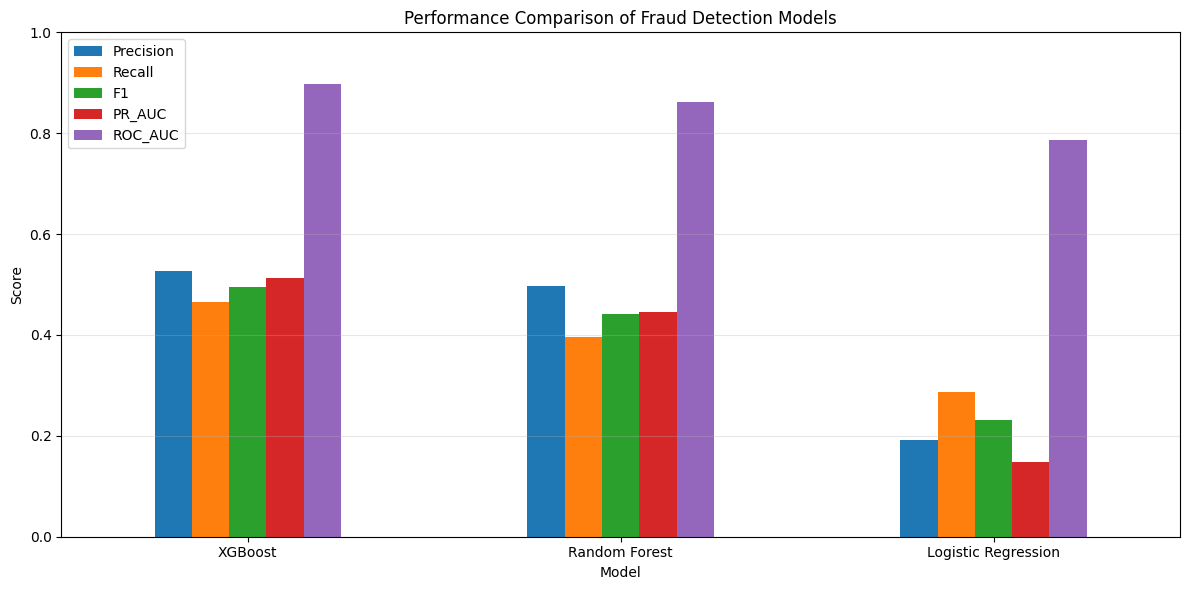

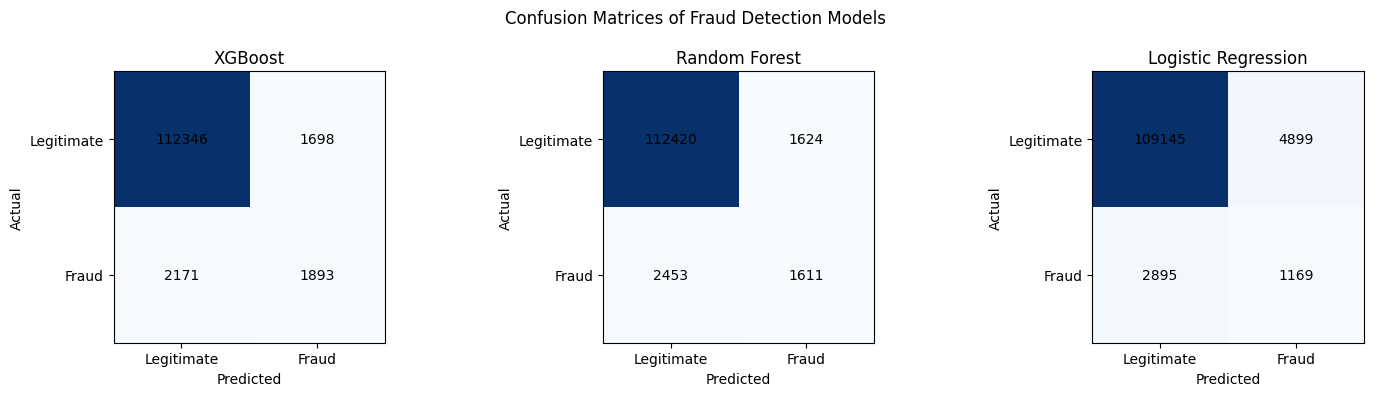

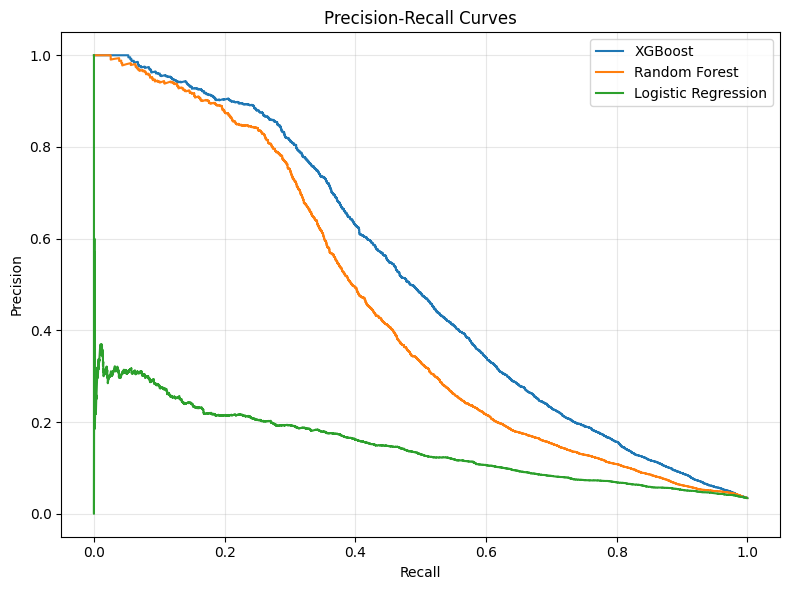

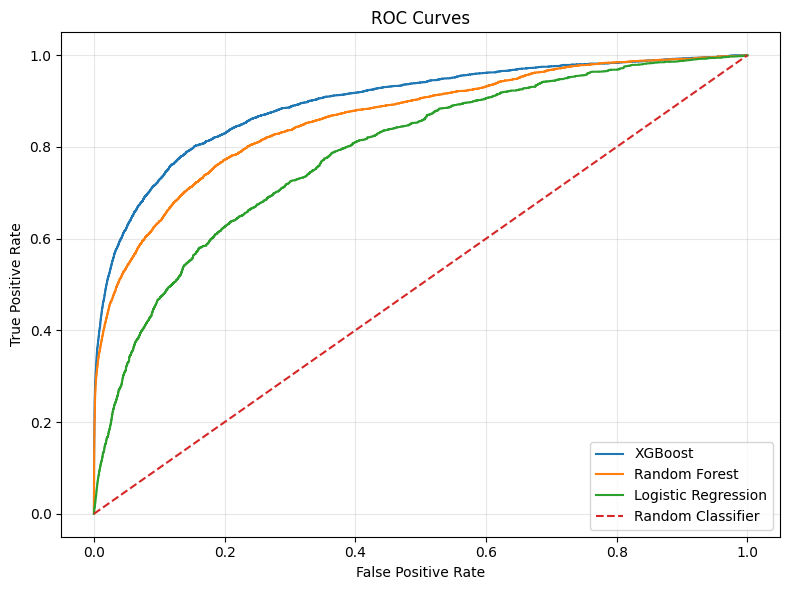

All comparison tables and graphs saved successfully.


In [ ]:

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_recall_curve,
    roc_curve,
    confusion_matrix
)

results_path = "/content/drive/MyDrive/Fraud_Detection_Project/Model_Results"

# Load saved metrics
xgb_metrics = pd.read_csv(
    os.path.join(results_path, "xgboost_test_metrics_retrained.csv")
)

rf_metrics = pd.read_csv(
    os.path.join(results_path, "random_forest_metrics.csv")
)

lr_metrics = pd.read_csv(
    os.path.join(results_path, "logistic_regression_metrics.csv")
)

# Standardize model names
xgb_metrics["Model"] = "XGBoost"
rf_metrics["Model"] = "Random Forest"
lr_metrics["Model"] = "Logistic Regression"

comparison = pd.concat(
    [xgb_metrics, rf_metrics, lr_metrics],
    ignore_index=True
)

comparison.to_csv(
    os.path.join(results_path, "model_comparison.csv"),
    index=False
)

display(comparison)

# Load predictions
xgb_pred = pd.read_csv(
    os.path.join(results_path, "xgboost_test_predictions_retrained.csv")
)

rf_pred = pd.read_csv(
    os.path.join(results_path, "random_forest_test_predictions.csv")
)

lr_pred = pd.read_csv(
    os.path.join(results_path, "logistic_regression_test_predictions.csv")
)

predictions = {
    "XGBoost": xgb_pred,
    "Random Forest": rf_pred,
    "Logistic Regression": lr_pred
}

# 1. Performance comparison
metrics_to_plot = [
    "Precision", "Recall", "F1", "PR_AUC", "ROC_AUC"
]

comparison.set_index("Model")[metrics_to_plot].plot(
    kind="bar", figsize=(12, 6), rot=0
)

plt.title("Performance Comparison of Fraud Detection Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend(loc="best")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(
    os.path.join(results_path, "model_performance_comparison.png"),
    dpi=300
)
plt.show()

# 2. Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, data) in zip(axes, predictions.items()):
    cm = confusion_matrix(data["Actual"], data["Predicted"])

    ax.imshow(cm, cmap="Blues")
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(["Legitimate", "Fraud"])
    ax.set_yticklabels(["Legitimate", "Fraud"])

    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]),
                    ha="center", va="center")

plt.suptitle("Confusion Matrices of Fraud Detection Models")
plt.tight_layout()
plt.savefig(
    os.path.join(results_path, "confusion_matrices.png"),
    dpi=300
)
plt.show()

# 3. Precision-Recall curves
plt.figure(figsize=(8, 6))

for name, data in predictions.items():
    precision, recall, _ = precision_recall_curve(
        data["Actual"], data["Fraud_Probability"]
    )

    plt.plot(recall, precision, label=name)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    os.path.join(results_path, "precision_recall_curves.png"),
    dpi=300
)
plt.show()

# 4. ROC curves
plt.figure(figsize=(8, 6))

for name, data in predictions.items():
    fpr, tpr, _ = roc_curve(
        data["Actual"], data["Fraud_Probability"]
    )

    plt.plot(fpr, tpr, label=name)

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    os.path.join(results_path, "roc_curves.png"),
    dpi=300
)
plt.show()

print("All comparison tables and graphs saved successfully.")


Saved XGBoost model and preprocessing loaded.
Test records loaded: 118108
SHAP sample shape: (500, 435)
SHAP values calculated successfully.
SHAP values shape: (500, 435)


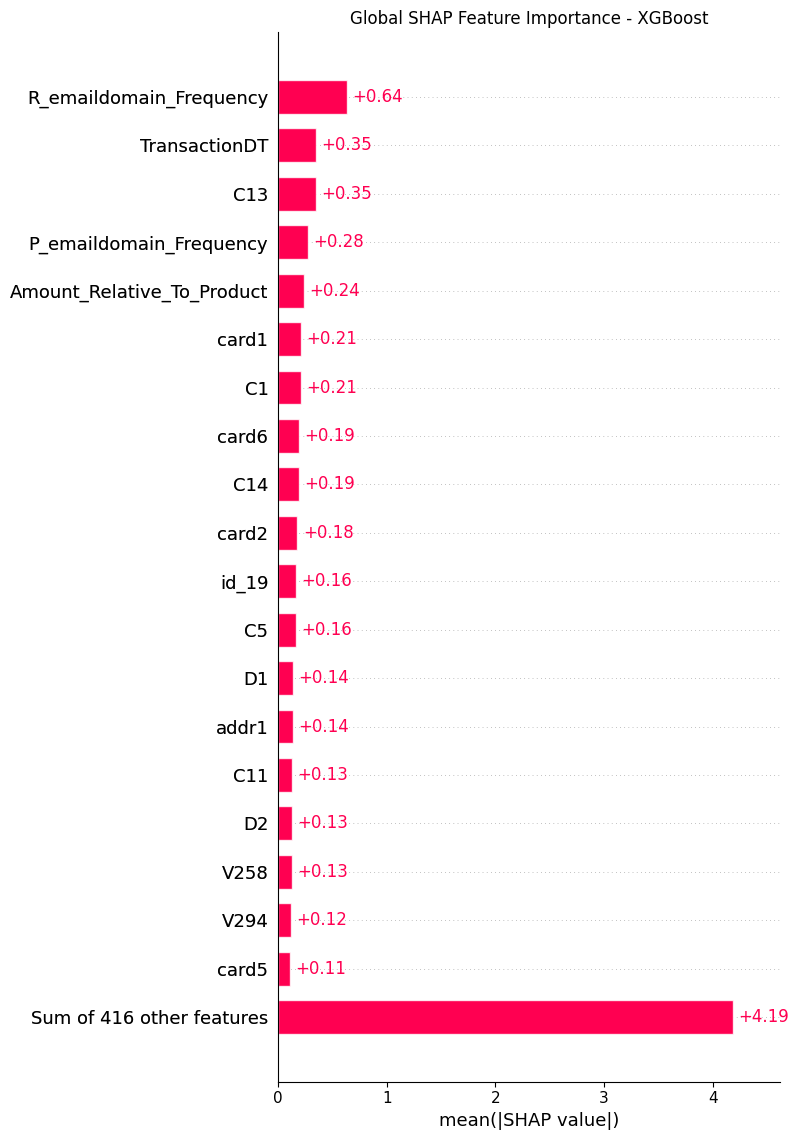

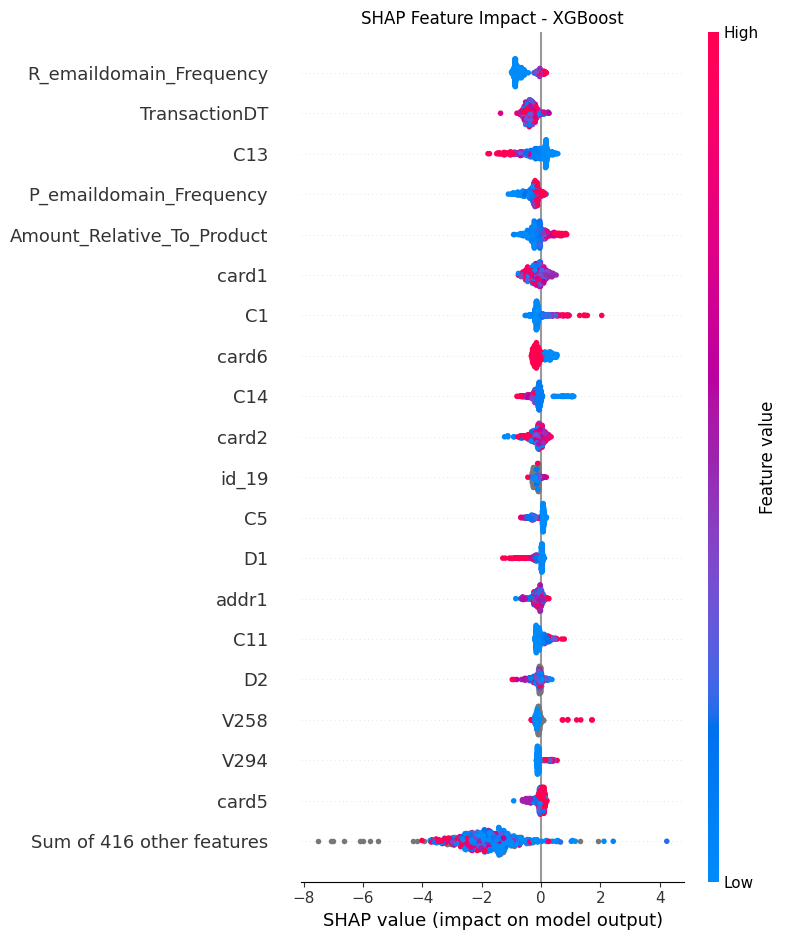


Selected transaction:
Transaction ID: 3516550
Actual label: 1
Predicted fraud probability: 0.99916816


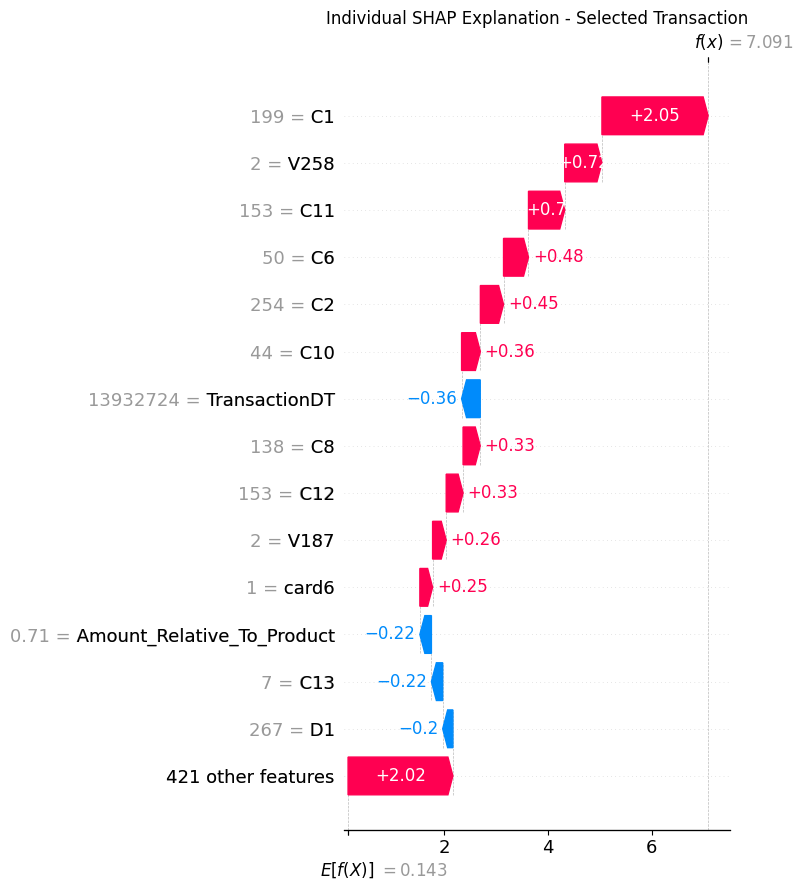


SHAP analysis completed.
Global importance, beeswarm, waterfall and SHAP data saved.

Top 5 features for selected transaction:


,Feature,Feature_Value,SHAP_Value,Absolute_Contribution
15,C1,199.0,2.049092,2.049092
310,V258,2.0,0.717802,0.717802
25,C11,153.0,0.699320,0.699320
20,C6,50.0,0.481533,0.481533
16,C2,254.0,0.447103,0.447103


In [ ]:

import os
import gc
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from xgboost import XGBClassifier

# --------------------------------------------------
# 1. Load saved model and preprocessing
# --------------------------------------------------

base_path = "/content/drive/MyDrive/Fraud_Detection_Project"
results_path = os.path.join(base_path, "Model_Results")

xgb_model = XGBClassifier()
xgb_model.load_model(
    os.path.join(results_path, "xgboost_model.json")
)

xgb_preprocessing = joblib.load(
    os.path.join(results_path, "xgboost_preprocessing.joblib")
)

product_medians = xgb_preprocessing["product_medians"]
global_median = xgb_preprocessing["global_median"]
p_email_counts = xgb_preprocessing["p_email_counts"]
r_email_counts = xgb_preprocessing["r_email_counts"]
encoder = xgb_preprocessing["encoder"]
cat_cols = xgb_preprocessing["cat_cols"]
feature_names = xgb_preprocessing["feature_names"]

print("Saved XGBoost model and preprocessing loaded.")

# --------------------------------------------------
# 2. Read only the columns needed for XGBoost
# --------------------------------------------------

engineered_cols = [
    "Amount_Relative_To_Product",
    "P_emaildomain_Frequency",
    "R_emaildomain_Frequency"
]

raw_feature_names = [
    col for col in feature_names
    if col not in engineered_cols
]

transaction_path = os.path.join(
    base_path, "train_transaction.csv"
)

identity_path = os.path.join(
    base_path, "train_identity.csv"
)

# Find identity columns required by the model
identity_header = pd.read_csv(
    identity_path, nrows=0
).columns.tolist()

identity_usecols = [
    col for col in identity_header
    if col in raw_feature_names or col == "TransactionID"
]

transaction_usecols = [
    col for col in raw_feature_names
    if col in pd.read_csv(transaction_path, nrows=0).columns
]

transaction_usecols += ["TransactionID", "isFraud"]

transactions = pd.read_csv(
    transaction_path,
    usecols=list(dict.fromkeys(transaction_usecols))
)

# Select the final 20% chronological test rows
n = len(transactions)
test_start = int(n * 0.80)

test_raw = transactions.iloc[test_start:].copy()

del transactions
gc.collect()

# Load identity records and merge
identity = pd.read_csv(
    identity_path,
    usecols=identity_usecols
)

test_raw = test_raw.merge(
    identity,
    on="TransactionID",
    how="left"
)

del identity
gc.collect()

print("Test records loaded:", len(test_raw))

# --------------------------------------------------
# 3. Recreate the original XGBoost features
# --------------------------------------------------

X_shap = test_raw.drop(
    columns=["isFraud", "TransactionID"]
).copy()

X_shap["Amount_Relative_To_Product"] = (
    X_shap["TransactionAmt"] /
    X_shap["ProductCD"].map(product_medians).fillna(global_median)
)

X_shap["P_emaildomain_Frequency"] = (
    X_shap["P_emaildomain"].map(p_email_counts).fillna(0)
)

X_shap["R_emaildomain_Frequency"] = (
    X_shap["R_emaildomain"].map(r_email_counts).fillna(0)
)

X_shap = X_shap.replace([np.inf, -np.inf], np.nan)

# Match exact training feature order
X_shap = X_shap[feature_names]

# Apply the already-fitted categorical encoder
X_shap[cat_cols] = encoder.transform(
    X_shap[cat_cols]
)

# --------------------------------------------------
# 4. Select a reproducible sample of 500 transactions
# --------------------------------------------------

sample_size = min(500, len(X_shap))

sample_indices = X_shap.sample(
    n=sample_size,
    random_state=42
).index

X_sample = X_shap.loc[sample_indices].copy()

sample_actual = (
    test_raw.loc[sample_indices, "isFraud"]
    .reset_index(drop=True)
)

sample_ids = (
    test_raw.loc[sample_indices, "TransactionID"]
    .reset_index(drop=True)
)

del X_shap, test_raw
gc.collect()

print("SHAP sample shape:", X_sample.shape)

# --------------------------------------------------
# 5. Calculate SHAP values
# --------------------------------------------------

explainer = shap.TreeExplainer(xgb_model)

shap_values = explainer(X_sample)

print("SHAP values calculated successfully.")
print("SHAP values shape:", shap_values.values.shape)

# --------------------------------------------------
# 6. Global feature importance: bar plot
# --------------------------------------------------

plt.figure()

shap.plots.bar(
    shap_values,
    max_display=20,
    show=False
)

plt.title("Global SHAP Feature Importance - XGBoost")
plt.tight_layout()

plt.savefig(
    os.path.join(results_path, "shap_global_importance.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# --------------------------------------------------
# 7. Global feature impact: beeswarm plot
# --------------------------------------------------

plt.figure()

shap.plots.beeswarm(
    shap_values,
    max_display=20,
    show=False
)

plt.title("SHAP Feature Impact - XGBoost")
plt.tight_layout()

plt.savefig(
    os.path.join(results_path, "shap_beeswarm.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# --------------------------------------------------
# 8. Individual transaction explanation
# --------------------------------------------------

# Select the transaction with the highest model fraud score
sample_probabilities = xgb_model.predict_proba(
    X_sample
)[:, 1]

case_index = int(np.argmax(sample_probabilities))

print("\nSelected transaction:")
print("Transaction ID:", sample_ids.iloc[case_index])
print("Actual label:", sample_actual.iloc[case_index])
print("Predicted fraud probability:", sample_probabilities[case_index])

shap.plots.waterfall(
    shap_values[case_index],
    max_display=15,
    show=False
)

plt.title("Individual SHAP Explanation - Selected Transaction")
plt.tight_layout()

plt.savefig(
    os.path.join(results_path, "shap_individual_waterfall.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# --------------------------------------------------
# 9. Save SHAP values and transaction information
# --------------------------------------------------

shap_df = pd.DataFrame(
    shap_values.values,
    columns=feature_names
)

shap_df.insert(0, "TransactionID", sample_ids.to_numpy())
shap_df.insert(1, "Actual", sample_actual.to_numpy())
shap_df["Fraud_Probability"] = sample_probabilities

shap_df.to_csv(
    os.path.join(results_path, "shap_sample_values.csv"),
    index=False
)

# Save top 5 contributing features for selected transaction
case_shap = pd.DataFrame({
    "Feature": feature_names,
    "Feature_Value": X_sample.iloc[case_index].to_numpy(),
    "SHAP_Value": shap_values.values[case_index]
})

case_shap["Absolute_Contribution"] = (
    case_shap["SHAP_Value"].abs()
)

case_shap = case_shap.sort_values(
    "Absolute_Contribution",
    ascending=False
)

case_shap.head(5).to_csv(
    os.path.join(results_path, "shap_selected_case_top5.csv"),
    index=False
)

# Save selected case metadata
pd.DataFrame([{
    "TransactionID": sample_ids.iloc[case_index],
    "Actual": sample_actual.iloc[case_index],
    "Fraud_Probability": sample_probabilities[case_index]
}]).to_csv(
    os.path.join(results_path, "shap_selected_case_info.csv"),
    index=False
)

print("\nSHAP analysis completed.")
print("Global importance, beeswarm, waterfall and SHAP data saved.")
print("\nTop 5 features for selected transaction:")
display(case_shap.head(5))


In [ ]:

import os
import pandas as pd
import numpy as np

results_path = "/content/drive/MyDrive/Fraud_Detection_Project/Model_Results"

# Load saved SHAP results
shap_df = pd.read_csv(
    os.path.join(results_path, "shap_sample_values.csv")
)

# 1. Global feature importance
metadata_cols = [
    "TransactionID", "Actual", "Fraud_Probability"
]

feature_cols = [
    col for col in shap_df.columns
    if col not in metadata_cols
]

global_importance = pd.DataFrame({
    "Feature": feature_cols,
    "Mean_Absolute_SHAP": shap_df[feature_cols].abs().mean().values
}).sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
)

global_importance.to_csv(
    os.path.join(results_path, "shap_global_feature_importance.csv"),
    index=False
)

print("TOP 15 GLOBAL FEATURES")
display(global_importance.head(15))

# 2. Classify the 500 sampled transactions
xgb_preprocessing = joblib.load(
    os.path.join(results_path, "xgboost_preprocessing.joblib")
)

threshold = xgb_preprocessing["best_threshold"]

shap_df["Predicted"] = (
    shap_df["Fraud_Probability"] >= threshold
).astype(int)

conditions = [
    (shap_df["Actual"] == 1) & (shap_df["Predicted"] == 1),
    (shap_df["Actual"] == 0) & (shap_df["Predicted"] == 0),
    (shap_df["Actual"] == 0) & (shap_df["Predicted"] == 1),
    (shap_df["Actual"] == 1) & (shap_df["Predicted"] == 0)
]

labels = [
    "True Positive",
    "True Negative",
    "False Positive",
    "False Negative"
]

shap_df["Case_Type"] = np.select(
    conditions,
    labels,
    default="Unknown"
)

# 3. Select one representative transaction of each type
selected_cases = []

for case_type in labels:
    subset = shap_df[shap_df["Case_Type"] == case_type].copy()

    if len(subset) == 0:
        print("No sampled case found for:", case_type)
        continue

    # Select the case closest to the relevant decision boundary
    if case_type in ["True Positive", "False Positive"]:
        selected = subset.sort_values(
            "Fraud_Probability", ascending=False
        ).iloc[0]
    else:
        selected = subset.sort_values(
            "Fraud_Probability", ascending=True
        ).iloc[0]

    selected_cases.append(selected)

case_summary = pd.DataFrame(selected_cases)[
    [
        "TransactionID",
        "Actual",
        "Fraud_Probability",
        "Predicted",
        "Case_Type"
    ]
]

case_summary.to_csv(
    os.path.join(results_path, "shap_representative_cases.csv"),
    index=False
)

print("\nREPRESENTATIVE DASHBOARD CASES")
display(case_summary)

print("\nSaved global importance and representative cases.")


TOP 15 GLOBAL FEATURES


,Feature,Mean_Absolute_SHAP
434,R_emaildomain_Frequency,0.637076
0,TransactionDT,0.352014
27,C13,0.345495
433,P_emaildomain_Frequency,0.275036
432,Amount_Relative_To_Product,0.235099
3,card1,0.214093
15,C1,0.206940
8,card6,0.193755
28,C14,0.191301
4,card2,0.178220



REPRESENTATIVE DASHBOARD CASES


,TransactionID,Actual,Fraud_Probability,Predicted,Case_Type
197,3516550,1,0.999168,1,True Positive
302,3525839,0,0.000055,0,True Negative
366,3539773,0,0.716493,1,False Positive
12,3459560,1,0.006271,0,False Negative



Saved global importance and representative cases.


In [ ]:
import pandas as pd
import os

BASE = "/content/drive/MyDrive/Fraud_Detection_Project/Model_Results"

cases = pd.read_csv(
    os.path.join(BASE, "shap_representative_cases.csv")
)

top5 = pd.read_csv(
    os.path.join(BASE, "shap_selected_case_top5.csv")
)

shap_sample = pd.read_csv(
    os.path.join(BASE, "shap_sample_values.csv")
)

print("REPRESENTATIVE CASES")
display(cases)

print("\nSELECTED CASE TOP 5 SHAP FEATURES")
display(top5)

print("\nSHAP SAMPLE SHAPE")
print(shap_sample.shape)

print("\nSHAP SAMPLE COLUMNS")
print(shap_sample.columns[:12].tolist())

REPRESENTATIVE CASES


,TransactionID,Actual,Fraud_Probability,Predicted,Case_Type
0,3516550,1,0.999168,1,True Positive
1,3525839,0,0.000055,0,True Negative
2,3539773,0,0.716493,1,False Positive
3,3459560,1,0.006271,0,False Negative



SELECTED CASE TOP 5 SHAP FEATURES


,Feature,Feature_Value,SHAP_Value,Absolute_Contribution
0,C1,199.0,2.049092,2.049092
1,V258,2.0,0.717802,0.717802
2,C11,153.0,0.699320,0.699320
3,C6,50.0,0.481533,0.481533
4,C2,254.0,0.447103,0.447103



SHAP SAMPLE SHAPE
(500, 438)

SHAP SAMPLE COLUMNS
['TransactionID', 'Actual', 'TransactionDT', 'TransactionAmt', 'ProductCD', 'card1', 'card2', 'card3', 'card4', 'card5', 'card6', 'addr1']


In [ ]:
import joblib
import os

BASE = "/content/drive/MyDrive/Fraud_Detection_Project/Model_Results"

prep = joblib.load(
    os.path.join(BASE, "xgboost_preprocessing.joblib")
)

print("Preprocessing artifact keys:")
print(list(prep.keys()))

print("\nFeature count:")
print(len(prep["feature_names"]))

print("\nCategorical columns:")
print(prep["cat_cols"])

Preprocessing artifact keys:
['encoder', 'product_medians', 'p_email_counts', 'r_email_counts', 'global_median', 'feature_names', 'cat_cols', 'best_threshold']

Feature count:
435

Categorical columns:
['ProductCD', 'card4', 'card6', 'P_emaildomain', 'R_emaildomain', 'M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9', 'id_12', 'id_15', 'id_16', 'id_23', 'id_27', 'id_28', 'id_29', 'id_30', 'id_31', 'id_33', 'id_34', 'id_35', 'id_36', 'id_37', 'id_38', 'DeviceType', 'DeviceInfo']


In [ ]:
import os
import joblib
import numpy as np
import pandas as pd
import xgboost as xgb
import shap

BASE = "/content/drive/MyDrive/Fraud_Detection_Project"
RESULTS = os.path.join(BASE, "Model_Results")

# Load saved model and preprocessing
prep = joblib.load(os.path.join(RESULTS, "xgboost_preprocessing.joblib"))

model = xgb.XGBClassifier()
model.load_model(os.path.join(RESULTS, "xgboost_model.json"))

# Load representative cases
cases = pd.read_csv(
    os.path.join(RESULTS, "shap_representative_cases.csv")
)

# Load original data
transactions = pd.read_csv(
    os.path.join(BASE, "train_transaction.csv")
)

identity = pd.read_csv(
    os.path.join(BASE, "train_identity.csv")
)

df = transactions.merge(identity, on="TransactionID", how="left")

# Recreate training-time feature engineering
df["Amount_Relative_To_Product"] = (
    df["TransactionAmt"] /
    df["ProductCD"].map(prep["product_medians"])
).fillna(
    df["TransactionAmt"] / prep["global_median"]
)

df["P_emaildomain_Frequency"] = (
    df["P_emaildomain"].map(prep["p_email_counts"]).fillna(0)
)

df["R_emaildomain_Frequency"] = (
    df["R_emaildomain"].map(prep["r_email_counts"]).fillna(0)
)

# Prepare the exact model features
feature_names = prep["feature_names"]
cat_cols = prep["cat_cols"]

X = df[feature_names].copy()

for col in cat_cols:
    X[col] = X[col].fillna("__MISSING__").astype(str)

X[cat_cols] = prep["encoder"].transform(X[cat_cols])

X = X[feature_names].astype(np.float32)

# Select the four representative transactions
case_ids = cases["TransactionID"].tolist()

X_cases = (
    X.loc[df["TransactionID"].isin(case_ids)]
    .copy()
)

X_cases.index = df.loc[
    df["TransactionID"].isin(case_ids),
    "TransactionID"
].values

X_cases = X_cases.loc[case_ids]

# Calculate SHAP values
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_cases)

shap_values = np.asarray(shap_values)

# Save top five SHAP features for each case
all_top_features = []

for transaction_id in case_ids:
    values = shap_values[case_ids.index(transaction_id)]

    top_indices = np.argsort(np.abs(values))[-5:][::-1]

    for rank, idx in enumerate(top_indices, start=1):
        all_top_features.append({
            "TransactionID": transaction_id,
            "Rank": rank,
            "Feature": feature_names[idx],
            "Feature_Value": X_cases.loc[transaction_id, feature_names[idx]],
            "SHAP_Value": values[idx],
            "Absolute_Contribution": abs(values[idx])
        })

top_features_df = pd.DataFrame(all_top_features)

top_features_df.to_csv(
    os.path.join(RESULTS, "shap_all_representative_cases_top5.csv"),
    index=False
)

print("SHAP explanations generated successfully.")
display(top_features_df)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
BASE = "/content/drive/MyDrive/Fraud_Detection_Project"
RESULTS = os.path.join(BASE, "Model_Results")

print("Saved files:")
print(os.listdir(RESULTS))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saved files:
['xgboost_complete.pkl', 'xgboost_test_predictions.csv', 'xgboost_results.csv', 'xgboost_model.json', 'xgboost_preprocessing.joblib', 'xgboost_test_predictions_retrained.csv', 'xgboost_test_metrics_retrained.csv', 'random_forest.joblib', 'random_forest_imputer.joblib', 'random_forest_test_predictions.csv', 'random_forest_metrics.csv', 'logistic_regression.joblib', 'logistic_regression_preprocessing.joblib', 'logistic_regression_test_predictions.csv', 'logistic_regression_metrics.csv', 'model_comparison.csv', 'model_performance_comparison.png', 'confusion_matrices.png', 'precision_recall_curves.png', 'roc_curves.png', 'shap_global_importance.png', 'shap_beeswarm.png', 'shap_individual_waterfall.png', 'shap_sample_values.csv', 'shap_selected_case_top5.csv', 'shap_selected_case_info.csv', 'shap_global_feature_importance.csv', 'shap_representative_ca

In [ ]:
import pandas as pd
import os

sample_path = os.path.join(RESULTS, "shap_sample_values.csv")
cases_path = os.path.join(RESULTS, "shap_representative_cases.csv")
top5_path = os.path.join(RESULTS, "shap_selected_case_top5.csv")

sample = pd.read_csv(sample_path)
cases = pd.read_csv(cases_path)
top5 = pd.read_csv(top5_path)

print("Sample shape:", sample.shape)
print("Sample columns:", sample.columns.tolist())
print("\nRepresentative cases:")
display(cases)

print("\nExisting top-five explanation:")
display(top5)

Sample shape: (500, 438)
Sample columns: ['TransactionID', 'Actual', 'TransactionDT', 'TransactionAmt', 'ProductCD', 'card1', 'card2', 'card3', 'card4', 'card5', 'card6', 'addr1', 'addr2', 'dist1', 'dist2', 'P_emaildomain', 'R_emaildomain', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9', 'C10', 'C11', 'C12', 'C13', 'C14', 'D1', 'D2', 'D3', 'D4', 'D5', 'D6', 'D7', 'D8', 'D9', 'D10', 'D11', 'D12', 'D13', 'D14', 'D15', 'M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'V29', 'V30', 'V31', 'V32', 'V33', 'V34', 'V35', 'V36', 'V37', 'V38', 'V39', 'V40', 'V41', 'V42', 'V43', 'V44', 'V45', 'V46', 'V47', 'V48', 'V49', 'V50', 'V51', 'V52', 'V53', 'V54', 'V55', 'V56', 'V57', 'V58', 'V59', 'V60', 'V61', 'V62', 'V63', 'V64', 'V65', 'V66', 'V67', 'V68', 'V69', 'V70', 'V71', 'V72', 'V73', 'V74', 'V75', 'V76

,TransactionID,Actual,Fraud_Probability,Predicted,Case_Type
0,3516550,1,0.999168,1,True Positive
1,3525839,0,0.000055,0,True Negative
2,3539773,0,0.716493,1,False Positive
3,3459560,1,0.006271,0,False Negative



Existing top-five explanation:


,Feature,Feature_Value,SHAP_Value,Absolute_Contribution
0,C1,199.0,2.049092,2.049092
1,V258,2.0,0.717802,0.717802
2,C11,153.0,0.699320,0.699320
3,C6,50.0,0.481533,0.481533
4,C2,254.0,0.447103,0.447103


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
RESULTS = "/content/drive/MyDrive/Fraud_Detection_Project/Model_Results"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import os

sample_path = os.path.join(RESULTS, "shap_sample_values.csv")
cases_path = os.path.join(RESULTS, "shap_representative_cases.csv")
top5_path = os.path.join(RESULTS, "shap_selected_case_top5.csv")

sample = pd.read_csv(sample_path)
cases = pd.read_csv(cases_path)
top5 = pd.read_csv(top5_path)

print("Sample shape:", sample.shape)
print("Sample columns:", sample.columns.tolist())
print("\nRepresentative cases:")
display(cases)

print("\nExisting top-five explanation:")
display(top5)

Sample shape: (500, 438)
Sample columns: ['TransactionID', 'Actual', 'TransactionDT', 'TransactionAmt', 'ProductCD', 'card1', 'card2', 'card3', 'card4', 'card5', 'card6', 'addr1', 'addr2', 'dist1', 'dist2', 'P_emaildomain', 'R_emaildomain', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9', 'C10', 'C11', 'C12', 'C13', 'C14', 'D1', 'D2', 'D3', 'D4', 'D5', 'D6', 'D7', 'D8', 'D9', 'D10', 'D11', 'D12', 'D13', 'D14', 'D15', 'M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'V29', 'V30', 'V31', 'V32', 'V33', 'V34', 'V35', 'V36', 'V37', 'V38', 'V39', 'V40', 'V41', 'V42', 'V43', 'V44', 'V45', 'V46', 'V47', 'V48', 'V49', 'V50', 'V51', 'V52', 'V53', 'V54', 'V55', 'V56', 'V57', 'V58', 'V59', 'V60', 'V61', 'V62', 'V63', 'V64', 'V65', 'V66', 'V67', 'V68', 'V69', 'V70', 'V71', 'V72', 'V73', 'V74', 'V75', 'V76

,TransactionID,Actual,Fraud_Probability,Predicted,Case_Type
0,3516550,1,0.999168,1,True Positive
1,3525839,0,0.000055,0,True Negative
2,3539773,0,0.716493,1,False Positive
3,3459560,1,0.006271,0,False Negative



Existing top-five explanation:


,Feature,Feature_Value,SHAP_Value,Absolute_Contribution
0,C1,199.0,2.049092,2.049092
1,V258,2.0,0.717802,0.717802
2,C11,153.0,0.699320,0.699320
3,C6,50.0,0.481533,0.481533
4,C2,254.0,0.447103,0.447103


In [ ]:
import os
import joblib
import numpy as np
import pandas as pd
import xgboost as xgb
import shap

BASE = "/content/drive/MyDrive/Fraud_Detection_Project"
RESULTS = os.path.join(BASE, "Model_Results")

# Load saved artifacts
prep = joblib.load(os.path.join(RESULTS, "xgboost_preprocessing.joblib"))

model = xgb.XGBClassifier()
model.load_model(os.path.join(RESULTS, "xgboost_model.json"))

sample = pd.read_csv(os.path.join(RESULTS, "shap_sample_values.csv"))
cases = pd.read_csv(os.path.join(RESULTS, "shap_representative_cases.csv"))

# Select only the four representative transactions
case_ids = cases["TransactionID"].tolist()

raw_cases = (
    sample[sample["TransactionID"].isin(case_ids)]
    .set_index("TransactionID")
    .loc[case_ids]
    .copy()
)

# Remove metadata and probability columns
drop_cols = ["TransactionID", "Actual", "Fraud_Probability"]
X_cases = raw_cases.drop(columns=drop_cols, errors="ignore")

# Recreate the exact model feature order
feature_names = prep["feature_names"]
cat_cols = prep["cat_cols"]

# Ensure all model features are present
X_cases = X_cases[feature_names].copy()

# Apply saved categorical encoder
for col in cat_cols:
    X_cases[col] = X_cases[col].fillna("__MISSING__").astype(str)

X_cases[cat_cols] = prep["encoder"].transform(X_cases[cat_cols])

X_cases = X_cases.astype(np.float32)

# Calculate SHAP for four rows only
explainer = shap.TreeExplainer(model)
values = explainer.shap_values(X_cases)

values = np.asarray(values)

# Extract top five features per transaction
records = []

for i, transaction_id in enumerate(case_ids):
    top_indices = np.argsort(np.abs(values[i]))[-5:][::-1]

    for rank, idx in enumerate(top_indices, 1):
        records.append({
            "TransactionID": transaction_id,
            "Rank": rank,
            "Feature": feature_names[idx],
            "Feature_Value": X_cases.iloc[i, idx],
            "SHAP_Value": values[i, idx],
            "Absolute_Contribution": abs(values[i, idx])
        })

result = pd.DataFrame(records)

output_path = os.path.join(
    RESULTS, "shap_all_representative_cases_top5.csv"
)

result.to_csv(output_path, index=False)

print("Saved:", output_path)
display(result)

Saved: /content/drive/MyDrive/Fraud_Detection_Project/Model_Results/shap_all_representative_cases_top5.csv


,TransactionID,Rank,Feature,Feature_Value,SHAP_Value,Absolute_Contribution
0,3516550,1,card3,0.062044,-1.293957,1.293957
1,3516550,2,card5,-0.029644,-0.966185,0.966185
2,3516550,3,TransactionDT,-0.359798,-0.867991,0.867991
3,3516550,4,Amount_Relative_To_Product,-0.222470,-0.800332,0.800332
4,3516550,5,C14,-0.064954,0.652820,0.652820
5,3525839,1,card3,-0.030071,-1.325781,1.325781
6,3525839,2,card5,-0.057198,-0.981303,0.981303
7,3525839,3,Amount_Relative_To_Product,0.413493,-0.899677,0.899677
8,3525839,4,TransactionDT,0.240235,-0.840386,0.840386
9,3525839,5,C14,-0.221138,0.645416,0.645416


In [ ]:
import numpy as np
import pandas as pd
import os
import joblib
import xgboost as xgb

BASE = "/content/drive/MyDrive/Fraud_Detection_Project"
RESULTS = os.path.join(BASE, "Model_Results")

prep = joblib.load(os.path.join(RESULTS, "xgboost_preprocessing.joblib"))

model = xgb.XGBClassifier()
model.load_model(os.path.join(RESULTS, "xgboost_model.json"))

sample = pd.read_csv(os.path.join(RESULTS, "shap_sample_values.csv"))
cases = pd.read_csv(os.path.join(RESULTS, "shap_representative_cases.csv"))

case_ids = cases["TransactionID"].tolist()

raw_cases = (
    sample[sample["TransactionID"].isin(case_ids)]
    .set_index("TransactionID")
    .loc[case_ids]
)

X_check = raw_cases.drop(
    columns=["TransactionID", "Actual", "Fraud_Probability"],
    errors="ignore"
)[prep["feature_names"]].copy()

# Check current values before encoding
print("Values before preprocessing:")
display(X_check[["card3", "card5", "C1", "C14"]])

# Apply the saved encoder
for col in prep["cat_cols"]:
    X_check[col] = X_check[col].fillna("__MISSING__").astype(str)

X_check[prep["cat_cols"]] = prep["encoder"].transform(
    X_check[prep["cat_cols"]]
)

X_check = X_check.astype(np.float32)

# Compare reproduced and saved probabilities
reproduced = model.predict_proba(X_check)[:, 1]

comparison = pd.DataFrame({
    "TransactionID": case_ids,
    "Saved_Probability": raw_cases["Fraud_Probability"].values,
    "Reproduced_Probability": reproduced,
    "Difference": np.abs(
        raw_cases["Fraud_Probability"].values - reproduced
    )
})

display(comparison)

print("Maximum probability difference:",
      comparison["Difference"].max())

Values before preprocessing:


,card3,card5,C1,C14
TransactionID,,,,
3516550,0.062044,-0.029644,2.049092,-0.064954
3525839,-0.030071,-0.057198,-0.069938,-0.221138
3539773,0.083567,0.013957,-0.039060,1.056037
3459560,-0.003944,-0.028966,0.136100,-0.201531


,TransactionID,Saved_Probability,Reproduced_Probability,Difference
0,3516550,0.999168,0.000214,0.998955
1,3525839,0.000055,0.000257,0.000202
2,3539773,0.716493,0.000226,0.716267
3,3459560,0.006271,0.000443,0.005828


Maximum probability difference: 0.9989546035863448


In [ ]:
import os
import gc
import joblib
import numpy as np
import pandas as pd
import xgboost as xgb

BASE = "/content/drive/MyDrive/Fraud_Detection_Project"
RESULTS = os.path.join(BASE, "Model_Results")

TRANSACTION_PATH = os.path.join(BASE, "train_transaction.csv")
IDENTITY_PATH = os.path.join(BASE, "train_identity.csv")

# --------------------------------------------------
# 1. Load saved model and preprocessing
# --------------------------------------------------

prep = joblib.load(
    os.path.join(RESULTS, "xgboost_preprocessing.joblib")
)

model = xgb.XGBClassifier()
model.load_model(
    os.path.join(RESULTS, "xgboost_model.json")
)

cases = pd.read_csv(
    os.path.join(RESULTS, "shap_representative_cases.csv")
)

case_ids = cases["TransactionID"].astype(int).tolist()
target_ids = set(case_ids)

print("Recovering transaction IDs:", case_ids)

# --------------------------------------------------
# 2. Recover only four original transaction rows
# --------------------------------------------------

transaction_parts = []

for chunk in pd.read_csv(TRANSACTION_PATH, chunksize=50000):
    matched = chunk[chunk["TransactionID"].isin(target_ids)]

    if not matched.empty:
        transaction_parts.append(matched)

    del chunk

transactions = pd.concat(transaction_parts, ignore_index=True)
del transaction_parts
gc.collect()

# --------------------------------------------------
# 3. Recover only their identity records
# --------------------------------------------------

identity_parts = []

for chunk in pd.read_csv(IDENTITY_PATH, chunksize=50000):
    matched = chunk[chunk["TransactionID"].isin(target_ids)]

    if not matched.empty:
        identity_parts.append(matched)

    del chunk

if identity_parts:
    identity = pd.concat(identity_parts, ignore_index=True)
else:
    identity = pd.DataFrame(columns=["TransactionID"])

del identity_parts
gc.collect()

# --------------------------------------------------
# 4. Merge and preserve case order
# --------------------------------------------------

df = transactions.merge(
    identity,
    on="TransactionID",
    how="left"
)

df = (
    df.set_index("TransactionID")
      .loc[case_ids]
      .reset_index()
)

print("\nRecovered transaction rows:", len(df))
print("Recovered identity rows:", identity["TransactionID"].nunique())

# --------------------------------------------------
# 5. Recreate training-time engineered features
# --------------------------------------------------

df["Amount_Relative_To_Product"] = (
    df["TransactionAmt"] /
    df["ProductCD"].map(prep["product_medians"])
).fillna(
    df["TransactionAmt"] / prep["global_median"]
)

df["P_emaildomain_Frequency"] = (
    df["P_emaildomain"]
    .map(prep["p_email_counts"])
    .fillna(0)
)

df["R_emaildomain_Frequency"] = (
    df["R_emaildomain"]
    .map(prep["r_email_counts"])
    .fillna(0)
)

# --------------------------------------------------
# 6. Apply saved categorical preprocessing
# --------------------------------------------------

feature_names = prep["feature_names"]
cat_cols = prep["cat_cols"]

X_cases = df[feature_names].copy()

for col in cat_cols:
    X_cases[col] = (
        X_cases[col]
        .fillna("__MISSING__")
        .astype(str)
    )

X_cases[cat_cols] = prep["encoder"].transform(
    X_cases[cat_cols]
)

X_cases = X_cases[feature_names].astype(np.float32)

# --------------------------------------------------
# 7. Reproduce model probabilities
# --------------------------------------------------

reproduced = model.predict_proba(X_cases)[:, 1]

comparison = cases[
    ["TransactionID", "Actual", "Fraud_Probability", "Predicted", "Case_Type"]
].copy()

comparison["Reproduced_Probability"] = reproduced

comparison["Difference"] = np.abs(
    comparison["Fraud_Probability"] -
    comparison["Reproduced_Probability"]
)

display(comparison)

max_difference = comparison["Difference"].max()

print("\nMaximum probability difference:", max_difference)

# --------------------------------------------------
# 8. Save recovered original inputs
# --------------------------------------------------

if max_difference < 0.0001:
    X_cases.insert(
        0, "TransactionID", case_ids
    )

    X_cases.to_csv(
        os.path.join(RESULTS, "verified_four_case_inputs.csv"),
        index=False
    )

    print("\nSUCCESS: Original inputs verified.")
    print("Saved: verified_four_case_inputs.csv")

else:
    print("\nWARNING: Probability validation failed.")
    print("Do not calculate or use new SHAP explanations yet.")

Recovering transaction IDs: [3516550, 3525839, 3539773, 3459560]

Recovered transaction rows: 4
Recovered identity rows: 3


,TransactionID,Actual,Fraud_Probability,Predicted,Case_Type,Reproduced_Probability,Difference
0,3516550,1,0.999168,1,True Positive,0.999168,2.422485e-09
1,3525839,0,0.000055,0,True Negative,0.000055,9.847942e-13
2,3539773,0,0.716493,1,False Positive,0.716493,1.707001e-09
3,3459560,1,0.006271,0,False Negative,0.006271,1.895623e-10



Maximum probability difference: 2.4224853234500188e-09

SUCCESS: Original inputs verified.
Saved: verified_four_case_inputs.csv


In [ ]:
import os
import joblib
import numpy as np
import pandas as pd
import xgboost as xgb
import shap

BASE = "/content/drive/MyDrive/Fraud_Detection_Project"
RESULTS = os.path.join(BASE, "Model_Results")

# Load saved model and verified inputs
prep = joblib.load(
    os.path.join(RESULTS, "xgboost_preprocessing.joblib")
)

model = xgb.XGBClassifier()
model.load_model(
    os.path.join(RESULTS, "xgboost_model.json")
)

verified = pd.read_csv(
    os.path.join(RESULTS, "verified_four_case_inputs.csv")
)

cases = pd.read_csv(
    os.path.join(RESULTS, "shap_representative_cases.csv")
)

case_ids = cases["TransactionID"].tolist()

X_cases = (
    verified.set_index("TransactionID")
    .loc[case_ids, prep["feature_names"]]
    .astype(np.float32)
)

# Calculate SHAP values for four transactions only
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_cases)

shap_values = np.asarray(shap_values)

# Verify SHAP output against model predictions
model_probabilities = model.predict_proba(X_cases)[:, 1]

verification = pd.DataFrame({
    "TransactionID": case_ids,
    "Saved_Probability": cases["Fraud_Probability"].values,
    "Reproduced_Probability": model_probabilities
})

print("Prediction verification:")
display(verification)

# Generate top five SHAP contributions per case
records = []

for i, transaction_id in enumerate(case_ids):
    top_indices = np.argsort(
        np.abs(shap_values[i])
    )[-5:][::-1]

    for rank, idx in enumerate(top_indices, start=1):
        records.append({
            "TransactionID": transaction_id,
            "Rank": rank,
            "Feature": prep["feature_names"][idx],
            "Feature_Value": X_cases.iloc[i, idx],
            "SHAP_Value": shap_values[i, idx],
            "Absolute_Contribution": abs(shap_values[i, idx])
        })

result = pd.DataFrame(records)

output_path = os.path.join(
    RESULTS,
    "shap_verified_representative_cases_top5.csv"
)

result.to_csv(output_path, index=False)

print("\nVerified SHAP explanations saved:")
print(output_path)

display(result)

Prediction verification:


,TransactionID,Saved_Probability,Reproduced_Probability
0,3516550,0.999168,0.999168
1,3525839,0.000055,0.000055
2,3539773,0.716493,0.716493
3,3459560,0.006271,0.006271



Verified SHAP explanations saved:
/content/drive/MyDrive/Fraud_Detection_Project/Model_Results/shap_verified_representative_cases_top5.csv


,TransactionID,Rank,Feature,Feature_Value,SHAP_Value,Absolute_Contribution
0,3516550,1,C1,1.990000e+02,2.049092,2.049092
1,3516550,2,V258,2.000000e+00,0.717802,0.717802
2,3516550,3,C11,1.530000e+02,0.699320,0.699320
3,3516550,4,C6,5.000000e+01,0.481533,0.481533
4,3516550,5,C2,2.540000e+02,0.447103,0.447103
5,3525839,1,V165,3.361000e+03,-0.773581,0.773581
6,3525839,2,D13,1.900000e+01,-0.743011,0.743011
7,3525839,3,C13,5.100000e+01,-0.692585,0.692585
8,3525839,4,P_emaildomain_Frequency,0.000000e+00,-0.683289,0.683289
9,3525839,5,card1,1.577500e+04,-0.505129,0.505129


In [ ]:
import os
import pandas as pd

BASE = "/content/drive/MyDrive/Fraud_Detection_Project"
RESULTS = os.path.join(BASE, "Model_Results")

cases = pd.read_csv(
    os.path.join(RESULTS, "shap_representative_cases.csv")
)

shap_data = pd.read_csv(
    os.path.join(RESULTS, "shap_verified_representative_cases_top5.csv")
)

# Convert SHAP rows into one dashboard record per transaction
dashboard = []

for _, case in cases.iterrows():

    tx_id = case["TransactionID"]

    features = shap_data[
        shap_data["TransactionID"] == tx_id
    ].sort_values("Rank")

    dashboard.append({
        "TransactionID": tx_id,
        "Actual": case["Actual"],
        "Predicted": case["Predicted"],
        "Fraud_Probability": case["Fraud_Probability"],
        "Case_Type": case["Case_Type"],
        "Top_Features": " | ".join(features["Feature"].astype(str)),
        "SHAP_Values": " | ".join(
            features["SHAP_Value"].map(lambda x: f"{x:.4f}")
        )
    })

dashboard_df = pd.DataFrame(dashboard)

dashboard_df.to_csv(
    os.path.join(RESULTS, "dashboard_case_data.csv"),
    index=False
)

display(dashboard_df)

print("Dashboard case data saved successfully.")

,TransactionID,Actual,Predicted,Fraud_Probability,Case_Type,Top_Features,SHAP_Values
0,3516550,1,1,0.999168,True Positive,C1 | V258 | C11 | C6 | C2,2.0491 | 0.7178 | 0.6993 | 0.4815 | 0.4471
1,3525839,0,0,0.000055,True Negative,V165 | D13 | C13 | P_emaildomain_Frequency | c...,-0.7736 | -0.7430 | -0.6926 | -0.6833 | -0.5051
2,3539773,0,1,0.716493,False Positive,C14 | TransactionDT | C13 | D8 | card1,1.0560 | -0.7058 | 0.4703 | -0.3296 | -0.2616
3,3459560,1,0,0.006271,False Negative,P_emaildomain_Frequency | R_emaildomain_Freque...,-0.7533 | -0.6164 | -0.5226 | -0.2816 | -0.2620


Dashboard case data saved successfully.


In [ ]:
import os
import pandas as pd
import ipywidgets as widgets
from IPython.display import display, clear_output, HTML

BASE = "/content/drive/MyDrive/Fraud_Detection_Project"
RESULTS = os.path.join(BASE, "Model_Results")

data = pd.read_csv(
    os.path.join(RESULTS, "dashboard_case_data.csv")
)

# Dashboard selection
dashboard_select = widgets.ToggleButtons(
    options=[
        ("A — Score Only", "A"),
        ("B — Technical SHAP", "B"),
        ("C — Plain Language", "C")
    ],
    description="View:"
)

case_select = widgets.Dropdown(
    options=[
        (f"{row.Case_Type} — {int(row.TransactionID)}",
         int(row.TransactionID))
        for row in data.itertuples()
    ],
    description="Case:"
)

output = widgets.Output()

def show_dashboard(change=None):

    with output:
        clear_output(wait=True)

        case = data[
            data["TransactionID"] == case_select.value
        ].iloc[0]

        probability = case["Fraud_Probability"] * 100
        prediction = "Fraud" if case["Predicted"] == 1 else "Non-fraud"
        actual = "Fraud" if case["Actual"] == 1 else "Non-fraud"

        print("=" * 55)

        if dashboard_select.value == "A":

            print("DASHBOARD A — SCORE ONLY")
            print("=" * 55)
            print(f"Transaction ID: {case['TransactionID']}")
            print(f"Fraud probability: {probability:.4f}%")
            print(f"Model prediction: {prediction}")

        elif dashboard_select.value == "B":

            print("DASHBOARD B — TECHNICAL SHAP EXPLANATION")
            print("=" * 55)
            print(f"Transaction ID: {case['TransactionID']}")
            print(f"Fraud probability: {probability:.4f}%")
            print(f"Model prediction: {prediction}")
            print("\nTop five feature contributions:")

            features = str(case["Top_Features"]).split(" | ")
            values = [
                float(x) for x in str(case["SHAP_Values"]).split(" | ")
            ]

            for feature, value in zip(features, values):
                direction = "towards fraud" if value > 0 else "away from fraud"
                print(f"{feature}: {value:+.4f} ({direction})")

            print("\nSHAP values represent contributions to model output")
            print("(raw score/log-odds), not probability percentages.")

        else:

            print("DASHBOARD C — PLAIN-LANGUAGE EXPLANATION")
            print("=" * 55)
            print(f"Transaction ID: {case['TransactionID']}")
            print(f"Fraud probability: {probability:.4f}%")
            print(f"Model assessment: {prediction}")

            features = str(case["Top_Features"]).split(" | ")
            values = [
                float(x) for x in str(case["SHAP_Values"]).split(" | ")
            ]

            supporting = sum(v > 0 for v in values)
            opposing = sum(v < 0 for v in values)

            print("\nHow to understand this result:")

            print(
                f"Among the five strongest individual signals, "
                f"{supporting} pushed the model's score towards fraud "
                f"and {opposing} pushed it away from fraud."
            )

            print(
                "These signals are patterns in the recorded transaction "
                "data. Their individual real-world meanings are not "
                "available because some dataset features are anonymized."
            )

        print("\nActual outcome (for researcher reference):", actual)
        print("Case type (for researcher reference):", case["Case_Type"])

dashboard_select.observe(show_dashboard, names="value")
case_select.observe(show_dashboard, names="value")

display(widgets.VBox([
    dashboard_select,
    case_select,
    output
]))

show_dashboard()

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Fraud_Detection_Project/Model_Results/dashboard_case_data.csv'

In [ ]:
import os

BASE = "/content/drive/MyDrive/Fraud_Detection_Project"
RESULTS = os.path.join(BASE, "Model_Results")

print("Drive folder exists:", os.path.exists(BASE))
print("Results folder exists:", os.path.exists(RESULTS))

if os.path.exists(RESULTS):
    print("\nFiles in Model_Results:")
    for f in os.listdir(RESULTS):
        print(f)

Drive folder exists: True
Results folder exists: True

Files in Model_Results:
xgboost_complete.pkl
xgboost_test_predictions.csv
xgboost_results.csv
xgboost_model.json
xgboost_preprocessing.joblib
xgboost_test_predictions_retrained.csv
xgboost_test_metrics_retrained.csv
random_forest.joblib
random_forest_imputer.joblib
random_forest_test_predictions.csv
random_forest_metrics.csv
logistic_regression.joblib
logistic_regression_metrics.csv
logistic_regression_test_predictions.csv
logistic_regression_preprocessing.joblib
model_comparison.csv
model_performance_comparison.png
confusion_matrices.png
precision_recall_curves.png
roc_curves.png
shap_global_importance.png
shap_beeswarm.png
shap_individual_waterfall.png
shap_sample_values.csv
shap_selected_case_top5.csv
shap_selected_case_info.csv
shap_global_feature_importance.csv
shap_representative_cases.csv
shap_all_representative_cases_top5.csv
verified_four_case_inputs.csv
shap_verified_representative_cases_top5.csv
dashboard_case_data.csv


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

print("MyDrive exists:",
      os.path.exists("/content/drive/MyDrive"))

if os.path.exists("/content/drive/MyDrive"):
    print("\nFolders in MyDrive:")
    for item in os.listdir("/content/drive/MyDrive"):
        print(item)


MyDrive exists: True

Folders in MyDrive:
Colab Notebooks
IMG-20240707-WA0062.jpg
24I-2617-tooba qasim-DS(A).pdf
Classroom
24i-2617.pdf
Tooba Binte - Assignment # 1.gdoc
CamScanner09-11-202423.56.pdf
task2.pptx
Tooba Binte - PowerPoint.gdoc
task1.pptx
Floor Plans.pdf
AttendanceSheet (1).gsheet
AttendanceSheet.gsheet
AttendanceSheet(24i26176).xlsx
drinks124i2617.xlsx
24I-2617.xlsx
Tooba Binte - Week # 06(Excel lab 2).gdoc
My Resume-24i-2617.pdf
Tooba Binte - PowerPoint Presentation.gdoc
242617.zip
booksstore_inventory.accdb
The Holy Prophet (PBUH) as a Leader.gslides
AttendanceSheet(24i26176).gsheet
24i-2617--ToobaQasim-DS-A.pdf
11. HTML Lab.gdoc
assign4.cpp.zip
group number _self marking_all group member name (1).docx
word shooter..2421840-DSA.zip
2421840 (1).pdf
2421840.pdf
CamScanner16-03-202523.26.pdf
assignment 1..24i-2617....ds-A.zip
ToobaQasim,24i-2617,DS-2A.pdf
Voice over
M. Morris Mano, Michael D. Ciletti - Digital Design_ With an Introduction to the Verilog HDL-Prentice Hall (

In [ ]:
import os
import pandas as pd

BASE = "/content/drive/MyDrive/Fraud_Detection_Project"
RESULTS = os.path.join(BASE, "Model_Results")

file_path = os.path.join(RESULTS, "dashboard_case_data.csv")

data = pd.read_csv(file_path)

print("Dashboard dataset loaded successfully!")
print("Shape:", data.shape)
print("\nColumns:")
print(data.columns.tolist())

display(data)

Dashboard dataset loaded successfully!
Shape: (4, 7)

Columns:
['TransactionID', 'Actual', 'Predicted', 'Fraud_Probability', 'Case_Type', 'Top_Features', 'SHAP_Values']


,TransactionID,Actual,Predicted,Fraud_Probability,Case_Type,Top_Features,SHAP_Values
0,3516550,1,1,0.999168,True Positive,C1 | V258 | C11 | C6 | C2,2.0491 | 0.7178 | 0.6993 | 0.4815 | 0.4471
1,3525839,0,0,0.000055,True Negative,V165 | D13 | C13 | P_emaildomain_Frequency | c...,-0.7736 | -0.7430 | -0.6926 | -0.6833 | -0.5051
2,3539773,0,1,0.716493,False Positive,C14 | TransactionDT | C13 | D8 | card1,1.0560 | -0.7058 | 0.4703 | -0.3296 | -0.2616
3,3459560,1,0,0.006271,False Negative,P_emaildomain_Frequency | R_emaildomain_Freque...,-0.7533 | -0.6164 | -0.5226 | -0.2816 | -0.2620


In [ ]:

import os
import shutil
import pandas as pd
import zipfile

BASE = "/content/drive/MyDrive/Fraud_Detection_Project"
RESULTS = os.path.join(BASE, "Model_Results")

PACKAGE = os.path.join(BASE, "Member2_Dashboard_Handover")
PARTICIPANT = os.path.join(PACKAGE, "Participant_Data")
RESEARCHER = os.path.join(PACKAGE, "Researcher_Only")
VISUALS = os.path.join(PACKAGE, "Visual_References")

for folder in [PARTICIPANT, RESEARCHER, VISUALS]:
    os.makedirs(folder, exist_ok=True)

# 1. Load verified dashboard data
data = pd.read_csv(
    os.path.join(RESULTS, "dashboard_case_data.csv")
)

# 2. Create participant-facing dataset
# Actual outcome and case type are deliberately excluded.
participant_data = data.drop(
    columns=["Actual", "Case_Type"],
    errors="ignore"
)

participant_data.to_csv(
    os.path.join(PARTICIPANT, "participant_dashboard_cases.csv"),
    index=False
)

# 3. Keep the complete dataset for researchers only
data.to_csv(
    os.path.join(RESEARCHER, "dashboard_case_data_researcher_only.csv"),
    index=False
)

# 4. Copy verified SHAP results for technical explanations
shap_file = "shap_verified_representative_cases_top5.csv"
shap_path = os.path.join(RESULTS, shap_file)

if os.path.exists(shap_path):
    shutil.copy2(shap_path, RESEARCHER)

# 5. Copy model evaluation CSVs
evaluation_files = [
    "model_comparison.csv",
    "xgboost_test_metrics_retrained.csv",
    "random_forest_metrics.csv",
    "logistic_regression_metrics.csv"
]

for filename in evaluation_files:
    source = os.path.join(RESULTS, filename)
    if os.path.exists(source):
        shutil.copy2(source, RESEARCHER)

# 6. Copy Python-generated visualizations
visual_files = [
    "model_performance_comparison.png",
    "confusion_matrices.png",
    "precision_recall_curves.png",
    "roc_curves.png",
    "shap_global_importance.png",
    "shap_beeswarm.png",
    "shap_individual_waterfall.png"
]

for filename in visual_files:
    source = os.path.join(RESULTS, filename)
    if os.path.exists(source):
        shutil.copy2(source, VISUALS)

# 7. Create implementation instructions
readme = """
MEMBER 2 - DASHBOARD HANDOVER

PROJECT:
Dual-Audience Visual Explanations for Black-Box Fraud Detection
in Digital Banking and FinTech.

DASHBOARD CONDITIONS:

A. SCORE-ONLY BASELINE
Show:
- Transaction ID
- Fraud probability
- Model prediction

B. TECHNICAL EXPLANATION
Show:
- Same transaction ID, probability and prediction
- Top SHAP features
- Signed SHAP contributions
- Technical explanation of positive and negative contributions

C. NONTECHNICAL EXPLANATION
Show:
- Same transaction ID, probability and prediction
- Plain-language explanation of factors pushing the score
  toward or away from fraud
- Avoid unexplained machine-learning terminology

IMPORTANT EXPERIMENTAL CONTROLS:

1. Use the same four transactions in all three conditions.
2. Use the same XGBoost predictions and probabilities.
3. Change only the explanation format between conditions.
4. Do not show Actual, Case_Type, TP, TN, FP or FN to participants.
5. Keep researcher-only data separate from participant screens.
6. Do not invent meanings for anonymized C, V or D features.
7. SHAP explains model contributions, not actual causes of fraud.
8. Positive SHAP values push the model output toward fraud;
   negative values push it away from fraud.
9. SHAP values here are in raw model-output/log-odds space,
   not probability percentage points.

DATA FILES:

Participant_Data:
participant_dashboard_cases.csv
Contains participant-safe fields only.

Researcher_Only:
Contains actual labels, case types, verified SHAP results
and model evaluation metrics. Do not expose to participants.

Visual_References:
Contains the Python-generated model and SHAP plots.

NOTE:
The four cases are demonstration cases, not a complete
human-study sample. Participant responses must be collected
and analyzed separately.
"""

with open(os.path.join(PACKAGE, "README_Member2.txt"), "w") as f:
    f.write(readme)

# 8. Create ZIP
zip_path = os.path.join(
    BASE,
    "Member2_Dashboard_Handover.zip"
)

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for root, dirs, files in os.walk(PACKAGE):
        for filename in files:
            full_path = os.path.join(root, filename)
            relative_path = os.path.relpath(full_path, PACKAGE)
            z.write(full_path, relative_path)

print("HANDOVER PACKAGE CREATED")
print("ZIP:", zip_path)
print("\nParticipant dataset:")
print(participant_data.to_string(index=False))
print("\nPackage contents:")
for root, dirs, files in os.walk(PACKAGE):
    for filename in files:
        print(os.path.relpath(os.path.join(root, filename), PACKAGE))


HANDOVER PACKAGE CREATED
ZIP: /content/drive/MyDrive/Fraud_Detection_Project/Member2_Dashboard_Handover.zip

Participant dataset:
 TransactionID  Predicted  Fraud_Probability                                                                   Top_Features                                     SHAP_Values
       3516550          1           0.999168                                                      C1 | V258 | C11 | C6 | C2      2.0491 | 0.7178 | 0.6993 | 0.4815 | 0.4471
       3525839          0           0.000055                             V165 | D13 | C13 | P_emaildomain_Frequency | card1 -0.7736 | -0.7430 | -0.6926 | -0.6833 | -0.5051
       3539773          1           0.716493                                         C14 | TransactionDT | C13 | D8 | card1   1.0560 | -0.7058 | 0.4703 | -0.3296 | -0.2616
       3459560          0           0.006271 P_emaildomain_Frequency | R_emaildomain_Frequency | TransactionDT | id_19 | C5 -0.7533 | -0.6164 | -0.5226 | -0.2816 | -0.2620

Package c

In [ ]:
from google.colab import files

zip_path = "/content/drive/MyDrive/Fraud_Detection_Project/Member2_Dashboard_Handover.zip"

files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from google.colab import drive
drive.mount("/content/drive")

import os
import gc
import joblib
import numpy as np
import pandas as pd
import xgboost as xgb

BASE = "/content/drive/MyDrive/Fraud_Detection_Project"
RESULTS = BASE + "/Model_Results"
OUT = RESULTS + "/Proper_Ablation_Study"
WORK = "/content/ablation_work"

os.makedirs(OUT, exist_ok=True)
os.makedirs(WORK, exist_ok=True)

# Load the original preprocessing information
prep = joblib.load(RESULTS + "/xgboost_preprocessing.joblib")

features = prep["feature_names"]
cat_cols = prep["cat_cols"]

print("Original feature count:", len(features))
print("Categorical feature count:", len(cat_cols))

# Read only columns required by the original model
transaction_path = BASE + "/train_transaction.csv"
identity_path = BASE + "/train_identity.csv"

transaction_header = pd.read_csv(transaction_path, nrows=0).columns
identity_header = pd.read_csv(identity_path, nrows=0).columns

transaction_cols = [
    c for c in features
    if c in transaction_header
]
transaction_cols += ["TransactionID", "isFraud"]

identity_cols = [
    c for c in features
    if c in identity_header
]
identity_cols += ["TransactionID"]

transaction_cols = list(dict.fromkeys(transaction_cols))
identity_cols = list(dict.fromkeys(identity_cols))

print("Loading transaction data...")
transactions = pd.read_csv(
    transaction_path,
    usecols=transaction_cols,
    low_memory=False
)

print("Loading identity data...")
identity = pd.read_csv(
    identity_path,
    usecols=identity_cols,
    low_memory=False
)

print("Merging...")
df = transactions.merge(
    identity,
    on="TransactionID",
    how="left"
)

del transactions, identity
gc.collect()

df.sort_values("TransactionDT", inplace=True)
df.reset_index(drop=True, inplace=True)

print("Merged shape:", df.shape)

# Chronological split boundaries
n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.80)

# Recreate original training-derived feature engineering
global_median = prep["global_median"]
product_medians = prep["product_medians"]
p_email_counts = prep["p_email_counts"]
r_email_counts = prep["r_email_counts"]

df["Amount_Relative_To_Product"] = (
    df["TransactionAmt"] /
    df["ProductCD"].map(product_medians).fillna(global_median)
)

df["P_emaildomain_Frequency"] = (
    df["P_emaildomain"].map(p_email_counts).fillna(0)
)

df["R_emaildomain_Frequency"] = (
    df["R_emaildomain"].map(r_email_counts).fillna(0)
)

# Create disk-backed matrices
shape = (n, len(features))

X_file = os.path.join(WORK, "X_all.dat")
X_disk = np.lib.format.open_memmap(
    X_file, mode="w+", dtype=np.float32, shape=shape
)

y = df["isFraud"].to_numpy(dtype=np.int8)
np.save(os.path.join(WORK, "y_all.npy"), y)

# Transform one split at a time
splits = [
    ("train", 0, train_end),
    ("validation", train_end, val_end),
    ("test", val_end, n)
]

for name, start, end in splits:
    print("Preparing:", name)

    part = df.iloc[start:end].reindex(columns=features).copy()

    part[cat_cols] = prep["encoder"].transform(
        part[cat_cols].astype("object")
    )

    part = part.replace([np.inf, -np.inf], np.nan)

    X_disk[start:end] = part.to_numpy(dtype=np.float32)

    del part
    gc.collect()

X_disk.flush()

del X_disk, df
gc.collect()

print("\nDATA PREPARATION COMPLETED")
print("Rows:", n)
print("Train:", train_end)
print("Validation:", val_end - train_end)
print("Test:", n - val_end)
print("Feature matrix saved:", X_file)
print("Target saved:", os.path.join(WORK, "y_all.npy"))


Mounted at /content/drive
Original feature count: 435
Categorical feature count: 31
Loading transaction data...
Loading identity data...
Merging...
Merged shape: (590540, 434)
Preparing: train
Preparing: validation
Preparing: test

DATA PREPARATION COMPLETED
Rows: 590540
Train: 413378
Validation: 59054
Test: 118108
Feature matrix saved: /content/ablation_work/X_all.dat
Target saved: /content/ablation_work/y_all.npy


In [ ]:

import os
import gc
import numpy as np
import pandas as pd
import xgboost as xgb

from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    average_precision_score, roc_auc_score,
    confusion_matrix, precision_recall_curve
)

WORK = "/content/ablation_work"
OUT = "/content/drive/MyDrive/Fraud_Detection_Project/Model_Results/Proper_Ablation_Study"

os.makedirs(OUT, exist_ok=True)

# Load disk-backed arrays without loading the entire matrix into RAM
X = np.load(WORK + "/X_all.dat", mmap_mode="r")
y = np.load(WORK + "/y_all.npy", mmap_mode="r")

prep = joblib.load(
    "/content/drive/MyDrive/Fraud_Detection_Project/Model_Results/xgboost_preprocessing.joblib"
)

features = prep["feature_names"]

n = len(y)
train_end = int(n * 0.70)
val_end = int(n * 0.80)

y_train = y[:train_end]
y_val = y[train_end:val_end]
y_test = y[val_end:]

# Original baseline results from the saved full-feature model
results = [{
    "Experiment": "Original XGBoost",
    "Precision": 0.527151,
    "Recall": 0.465797,
    "F1": 0.494579,
    "PR_AUC": 0.513776,
    "ROC_AUC": 0.896898,
    "TN": 112346,
    "FP": 1698,
    "FN": 2171,
    "TP": 1893,
    "Threshold": 0.573607
}]

def get_metrics(y_true, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, predictions, labels=[0, 1]
    ).ravel()

    return {
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1": f1_score(y_true, predictions, zero_division=0),
        "PR_AUC": average_precision_score(y_true, probabilities),
        "ROC_AUC": roc_auc_score(y_true, probabilities),
        "TN": int(tn), "FP": int(fp),
        "FN": int(fn), "TP": int(tp),
        "Threshold": float(threshold)
    }

def choose_threshold(y_true, probabilities):
    p, r, thresholds = precision_recall_curve(y_true, probabilities)

    f1_values = (
        2 * p[:-1] * r[:-1] /
        (p[:-1] + r[:-1] + 1e-12)
    )

    return float(thresholds[np.argmax(f1_values)])

experiments = [
    (
        "Without engineered features",
        [
            "Amount_Relative_To_Product",
            "P_emaildomain_Frequency",
            "R_emaildomain_Frequency"
        ]
    ),
    (
        "Without identity features",
        [f for f in features if f.startswith("id_")]
    )
]

for experiment_name, removed_features in experiments:

    print("\n" + "=" * 55)
    print("RUNNING:", experiment_name)
    print("=" * 55)

    keep = [
        i for i, f in enumerate(features)
        if f not in removed_features
    ]

    print("Features retained:", len(keep))
    print("Features removed:", len(removed_features))

    # Load only this experiment's feature columns
    X_train = np.asarray(X[:train_end, keep], dtype=np.float32)
    X_val = np.asarray(X[train_end:val_end, keep], dtype=np.float32)
    X_test = np.asarray(X[val_end:, keep], dtype=np.float32)

    model = xgb.XGBClassifier(
        n_estimators=1000,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=27.43,
        objective="binary:logistic",
        eval_metric="aucpr",
        tree_method="hist",
        max_bin=256,
        early_stopping_rounds=50,
        random_state=42,
        n_jobs=2
    )

    model.fit(
        X_train,
        y_train,
        eval_set=[(X_val, y_val)],
        verbose=100
    )

    # Select threshold using validation set only
    val_probabilities = model.predict_proba(X_val)[:, 1]
    threshold = choose_threshold(y_val, val_probabilities)

    # Evaluate once on the untouched test set
    test_probabilities = model.predict_proba(X_test)[:, 1]

    row = {
        "Experiment": experiment_name,
        **get_metrics(y_test, test_probabilities, threshold)
    }

    results.append(row)

    # Save model and results immediately
    model_filename = (
        experiment_name.lower().replace(" ", "_") + ".json"
    )
    model.save_model(os.path.join(OUT, model_filename))

    results_df = pd.DataFrame(results)
    results_df.to_csv(
        os.path.join(OUT, "ablation_results.csv"),
        index=False
    )

    print("\nRESULT:")
    print(pd.DataFrame([row]).round(4).to_string(index=False))

    del X_train, X_val, X_test
    del model, val_probabilities, test_probabilities
    gc.collect()

print("\n" + "=" * 55)
print("FINAL ABLATION COMPARISON")
print("=" * 55)

results_df = pd.DataFrame(results)
print(results_df.round(4).to_string(index=False))

print("\nResults saved at:")
print(os.path.join(OUT, "ablation_results.csv"))



RUNNING: Without engineered features
Features retained: 432
Features removed: 3
[0]	validation_0-aucpr:0.34987
[100]	validation_0-aucpr:0.53646
[200]	validation_0-aucpr:0.56948
[300]	validation_0-aucpr:0.58833
[400]	validation_0-aucpr:0.59995
[500]	validation_0-aucpr:0.61007
[600]	validation_0-aucpr:0.61907
[700]	validation_0-aucpr:0.62620
[800]	validation_0-aucpr:0.62969
[900]	validation_0-aucpr:0.63361
[999]	validation_0-aucpr:0.63536

RESULT:
                 Experiment  Precision  Recall     F1  PR_AUC  ROC_AUC     TN   FP   FN   TP  Threshold
Without engineered features     0.5706  0.4397 0.4967  0.5087   0.8911 112699 1345 2277 1787     0.6304

RUNNING: Without identity features
Features retained: 397
Features removed: 38
[0]	validation_0-aucpr:0.33477
[100]	validation_0-aucpr:0.54212
[200]	validation_0-aucpr:0.56979
[300]	validation_0-aucpr:0.58522
[400]	validation_0-aucpr:0.59716
[500]	validation_0-aucpr:0.60474
[600]	validation_0-aucpr:0.61043
[700]	validation_0-aucpr:0.61901